# From AI that breaks to AI that is weaponised

Data: the AI Incident Database (AIID), export of 19 October 2026, with 1,749 incidents and 7,955 news reports.

**Hypotheses.** The project asks three questions about AI incidents:

* **H1 – Harm comes from misuse.** AI harm increasingly comes from people using AI on purpose, not from AI failing on its own.
* **H2 – Nobody to blame.** The harm increasingly comes from actors nobody can name (scammers, unknown deepfake creators) instead of identifiable companies.
* **H3 – Harm gets personal.** Harm moves from whole groups treated unfairly by a system to specific people who are targeted.

Sections 3–8 explore them; section 9 tests them formally.

## 1. Setup

In [1]:
import re
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from IPython.display import display

In [2]:
DATA_FILE = Path("data/raw/AIID_Excel_Export-20261019.xlsx")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
SNAPSHOT = "19 Oct 2026"
SEED = 42

In [3]:
DOMAINS = ["Malicious use", "System failures", "Discrimination & toxicity", "Misinformation",
           "Privacy & security", "Human-computer interaction", "Socioeconomic & environmental"]

DOM_COLOR = {"Malicious use": "#EE7733",
             "System failures": "#0077BB",
             "Discrimination & toxicity": "#AA4499",
             "Misinformation": "#DDCC77",
             "Privacy & security": "#44AA99",
             "Human-computer interaction": "#88CCEE",
             "Socioeconomic & environmental": "#332288",
             "Unclassified": "#DDDDDD"}

# light fills where white text is hard to read
DARK_TEXT = ["Malicious use", "Misinformation", "Privacy & security", "Human-computer interaction", "Unclassified"]

INK = "#2B2B2B"
CMP_A, CMP_B = "#225555", "#A6A6A6"
HIGHLIGHT = "#CC3311"
SEQ = LinearSegmentedColormap.from_list("seq", ["#F4F4FA", "#332288"])

In [4]:
sns.set_theme(style="white")
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"],
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 200,
})

def titles(ax, title, sub=None):
    ax.set_title(title, pad=24 if sub else 10)
    if sub:
        ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=9.5, color="#5A5A5A", va="bottom")

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")

def domain_legend(ax, names=DOMAINS + ["Unclassified"], **kw):
    handles = [plt.Line2D([], [], marker="s", ls="", color=DOM_COLOR[n], markersize=10, label=n) for n in names]
    return ax.legend(handles=handles, **kw)

## 2. Data

The Excel export has five sheets. We use **Incidents** (one row per incident), **Reports** (one row per news article) and the **Data Dictionary** to check the fill rates. The Entities sheet only lists entity names with no link to incidents, so it is not loaded.

In [5]:
inc_raw = pd.read_excel(DATA_FILE, sheet_name="Incidents", header=2)
rep_raw = pd.read_excel(DATA_FILE, sheet_name="Reports", header=1)
data_dict = pd.read_excel(DATA_FILE, sheet_name="Data Dictionary", header=1)

print(f"Incidents: {inc_raw.shape[0]:,} rows, {inc_raw.shape[1]} columns")
print(f"Reports:   {rep_raw.shape[0]:,} rows, {rep_raw.shape[1]} columns")

Incidents: 1,749 rows, 59 columns
Reports:   7,955 rows, 12 columns


In [6]:
print("Incident ID unique:", inc_raw["Incident ID"].is_unique)
print("Dates from", inc_raw["date"].min().date(), "to", inc_raw["date"].max().date())
display(data_dict["Group"].value_counts().to_frame("columns"))
display(inc_raw[["Incident ID", "date", "title", "deployer", "developer", "harmed", "Risk Domain", "Intent"]].head(3))

Incident ID unique: True
Dates from 1983-09-26 to 2026-10-07


,columns
Group,
CSETv1,35
Identity,12
MIT,5
GMF,5
Coverage,2


,Incident ID,date,title,deployer,developer,harmed,Risk Domain,Intent
0,1,2015-05-19,Google’s YouTube Kids App Presents Inappropria...,Youtube,Youtube,Minors,Discrimination and Toxicity,Unintentional
1,2,2018-12-05,Warehouse robot ruptures can of bear spray and...,Amazon,Amazon,Warehouse Workers,"AI system safety, failures, and limitations",Unintentional
2,3,2018-10-27,Crashes with Maneuvering Characteristics Augme...,Boeing,Boeing,"Airplane Passengers, Airplane Crew","AI system safety, failures, and limitations",Unintentional


### 2.1 Missing values

Some columns are not really blank when they are empty: they contain `[]`.

In [7]:
empty_lists = (inc_raw.astype(str) == "[]").sum()
empty_lists[empty_lists > 0].sort_values(ascending=False).to_frame("cells with []")

,cells with []
Infrastructure Sectors,152
AI Methods,12
AI Task,12
Harm Distribution Basis,9
Sector of Deployment,6


In [8]:
def empty_share(df):
    empty = df.isna() | df.astype(str).apply(lambda s: s.str.strip().isin(["", "[]"]))
    return (empty.mean() * 100).round(1)

fill = data_dict.set_index("Column")[["Group", "Fill Rate"]]
fill["dictionary %"] = fill["Fill Rate"].str.rstrip("%").astype(float)
fill["actual %"] = 100 - empty_share(inc_raw)

display(fill.groupby("Group", sort=False)["actual %"].agg(["count", "min", "median", "max"]).round(0))
print("Columns where the dictionary is off by 2 points or more:")
display(fill.loc[(fill["actual %"] - fill["dictionary %"]).abs() >= 2, ["Group", "dictionary %", "actual %"]])

,count,min,median,max
Group,,,,
Identity,12,30.0,100.0,100.0
Coverage,2,86.0,93.0,100.0
MIT,5,86.0,86.0,86.0
GMF,5,2.0,2.0,2.0
CSETv1,35,3.0,11.0,12.0


Columns where the dictionary is off by 2 points or more:


,Group,dictionary %,actual %
Column,,,
Implicated Systems,Identity,100.0,68.6
Editor Notes,Identity,100.0,30.4
Data Sources,Coverage,100.0,85.5
Infrastructure Sectors,CSETv1,12.0,3.1
Country Code,CSETv1,12.0,8.0
Incident Month,CSETv1,12.0,8.2
Incident Day,CSETv1,12.0,4.2
AI Task,CSETv1,12.0,9.6
AI Methods,CSETv1,12.0,5.2


In [9]:
empty_share(rep_raw).to_frame("empty %")

,empty %
Report Number,0.0
Title,10.2
URL,10.2
Source Domain,10.2
Date Published,0.0
Date Downloaded,0.0
Authors,10.2
Submitters,0.0
Language,0.0
Tags,79.5


The basic fields (title, description, deployer, developer, harmed) are complete. The MIT risk taxonomy covers 86% of incidents, CSET about 11% and GMF only 1-2%, so the analysis is built on the MIT fields.

The Data Dictionary fill rates are not always right. It says 100% for *Implicated Systems*, *Editor Notes* and *Data Sources*, but they are filled for 69%, 30% and 86% of incidents. Several CSET columns also drop when `[]` is counted as empty (e.g. *Infrastructure Sectors* from 12% to 3%). We use our own numbers.

In the reports, about 10% have no title, URL, source or authors; these are checked in the report cleaning section.

### 2.2 Risk domains

The MIT taxonomy puts each incident in one of seven risk domains. Two of them are much smaller than the rest.

In [10]:
dom = inc_raw["Risk Domain"].fillna("Not classified").value_counts().to_frame("incidents")
dom["% of all"] = (dom["incidents"] / len(inc_raw) * 100).round(1)
display(dom)

small = inc_raw[inc_raw["Risk Domain"].isin(["Human-Computer Interaction", "Socioeconomic & Environmental Harms"])]
pd.crosstab(small["Risk Subdomain"], small["Risk Domain"])

,incidents,% of all
Risk Domain,,
Malicious Actors & Misuse,566,32.4
"AI system safety, failures, and limitations",313,17.9
Not classified,253,14.5
Discrimination and Toxicity,243,13.9
Misinformation,196,11.2
Privacy & Security,112,6.4
Human-Computer Interaction,42,2.4
Socioeconomic & Environmental Harms,24,1.4


Risk Domain,Human-Computer Interaction,Socioeconomic & Environmental Harms
Risk Subdomain,,
Competitive dynamics,0,3
Economic and cultural devaluation of human effort,0,5
Environmental harm,0,1
Governance failure,0,3
Increased inequality and decline in employment quality,0,6
Loss of human agency and autonomy,4,0
Overreliance and unsafe use,38,0
Power centralization and unfair distribution of benefits,0,6


The two small domains are about different things (over-reliance on AI vs. jobs, power and the environment), so merging them into "Other" would mix unrelated topics. We keep all seven domains.

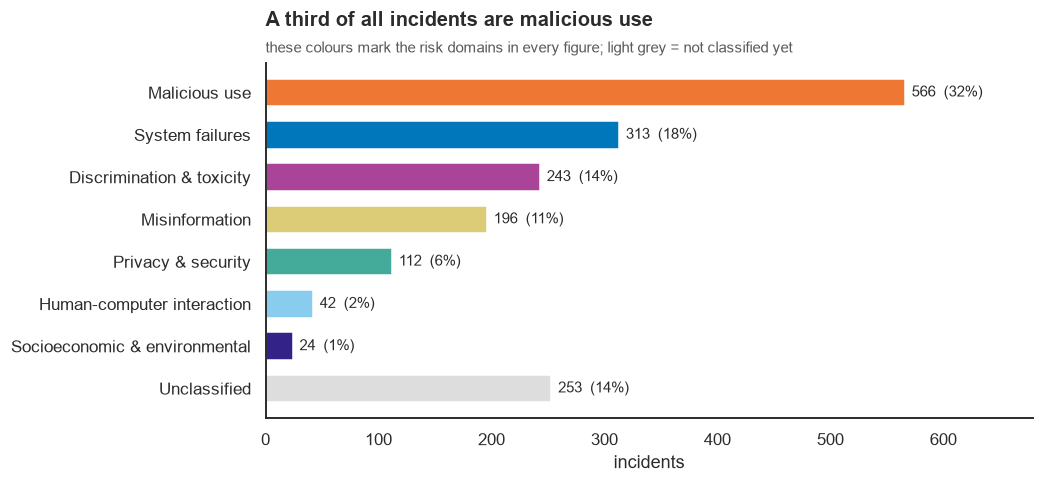

In [11]:
DOMAIN_MAP = {"Malicious Actors & Misuse": "Malicious use",
              "AI system safety, failures, and limitations": "System failures",
              "Discrimination and Toxicity": "Discrimination & toxicity",
              "Misinformation": "Misinformation",
              "Privacy & Security": "Privacy & security",
              "Human-Computer Interaction": "Human-computer interaction",
              "Socioeconomic & Environmental Harms": "Socioeconomic & environmental"}

domain = inc_raw["Risk Domain"].map(DOMAIN_MAP).fillna("Unclassified")
counts = domain.value_counts().reindex(DOMAINS + ["Unclassified"])[::-1]

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(counts.index, counts.values, color=[DOM_COLOR[d] for d in counts.index], height=0.65)
for y, v in enumerate(counts.values):
    ax.text(v + 6, y, f"{v}  ({v / len(inc_raw):.0%})", va="center", fontsize=10)
ax.set_xlim(0, counts.max() * 1.2)
ax.set_xlabel("incidents")
titles(ax, "A third of all incidents are malicious use",
       "these colours mark the risk domains in every figure; light grey = not classified yet")
save(fig, "00a_risk_domains")
plt.show()

In [12]:
unclassified = inc_raw["Risk Domain"].isna()
unclassified.groupby(inc_raw["year"] >= 2025).agg(["sum", "mean"]).rename(index={False: "before 2025", True: "2025-26"})

,sum,mean
year,,
before 2025,36,0.035225
2025-26,217,0.298487


253 incidents (14%) have no risk domain yet, and 86% of them are from 2025-26 (30% of that period vs 4% before).

### 2.3 Intent

The MIT taxonomy also records whether the harm was intentional. Besides *Intentional* and *Unintentional* there is a small *Other* group.

In [13]:
display(inc_raw["Intent"].value_counts(dropna=False).to_frame("incidents"))
print("Other incidents are often unclassified, and include a wide range of cases:")
inc_raw.loc[inc_raw["Intent"] == "Other", ["Risk Domain", "title"]].head(10)

,incidents
Intent,
Unintentional,740
Intentional,735
NaN,253
Other,21


Other incidents are often unclassified, and include a wide range of cases:


,Risk Domain,title
14,Discrimination and Toxicity,Amazon Censors Gay Books
20,"AI system safety, failures, and limitations",Tougher Turing Test Exposes Chatbots’ Stupidit...
41,Socioeconomic & Environmental Harms,Inefficiencies in the United States Resident M...
61,"AI system safety, failures, and limitations",Bad AI-Written Christmas Carols
84,"AI system safety, failures, and limitations","AI attempts to ease fear of robots, blurts out..."
155,"AI system safety, failures, and limitations",Tesla Autopilot’s Lane Recognition Allegedly V...
280,"AI system safety, failures, and limitations",OpenAI’s GPT-3 Reported as Unviable in Medical...
291,"AI system safety, failures, and limitations",Student-Developed Facial Recognition App Raise...
643,Privacy & Security,Alleged ChatGPT Account Compromise Reportedly ...
683,Malicious Actors & Misuse,Purported Deepfake Image Allegedly Circulating...


The 21 *Other* incidents are a mix of everything (bad chatbot answers, deepfakes, data leaks), so they don't form a third type of intent. They are left out of the intent analysis only; everywhere else they stay in.

In [14]:
INTENTS = ["Intentional", "Unintentional"]
inc_raw["Intent"].where(inc_raw["Intent"].isin(INTENTS)).value_counts(dropna=False)

Intent
Unintentional    740
Intentional      735
NaN              274
Name: count, dtype: int64

### 2.4 Years and periods

Most years before 2015 have only a few incidents, and 2026 stops in October.

In [15]:
per_year = inc_raw["year"].value_counts().sort_index()
print("Years before 2012:", per_year[per_year.index < 2012].sum(), "incidents in total")
print("Last date in 2026:", inc_raw.loc[inc_raw["year"] == 2026, "date"].max().date())
per_year[per_year.index >= 2012].to_frame("incidents").T

Years before 2012: 20 incidents in total
Last date in 2026: 2026-10-07


year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
incidents,8,6,13,24,41,50,46,45,91,80,109,179,310,460,267


In [16]:
PERIODS = ["up to 2018", "2019-22", "2023-24", "2025-26"]
period = pd.cut(inc_raw["year"], [0, 2018, 2022, 2024, 2026], labels=PERIODS)
period.value_counts().reindex(PERIODS).to_frame("incidents").T

year,up to 2018,2019-22,2023-24,2025-26
incidents,208,325,489,727


Single years are fine for counts, but shares need larger groups, so we also use four periods. The early years are merged into *up to 2018* because they are too small on their own, and 2023-24 and 2025-26 are two years each. 2026 is only partial (until 7 October), so it is shown hatched or marked in the yearly charts.

### 2.5 Entities: deployer, developer, harmed

These fields are lists of names written as one text, separated by commas. Before counting "who" appears most often we check three things: unknown values, the same name written in different ways, and companies that changed their name.

In [17]:
def tokens(s):
    return [] if pd.isna(s) else [t.strip() for t in str(s).split(",") if t.strip()]

FIELDS = ["deployer", "developer", "harmed"]
mentions = {f: inc_raw[f].map(tokens).explode().dropna() for f in FIELDS}

pd.DataFrame({
    "mentions": {f: len(m) for f, m in mentions.items()},
    "different names": {f: m.nunique() for f, m in mentions.items()},
    "exactly 'Unknown'": {f: (m.str.lower() == "unknown").sum() for f, m in mentions.items()},
    "'Unknown ...' variants": {f: m[m.str.lower().str.startswith("unknown ")].nunique() for f, m in mentions.items()},
})

,mentions,different names,exactly 'Unknown','Unknown ...' variants
deployer,3887,2021,25,137
developer,3111,732,80,27
harmed,7468,3791,4,1


In [18]:
actors = pd.concat([mentions["deployer"], mentions["developer"]])
actors[actors.str.lower().str.startswith("unknown")].value_counts().head(10).to_frame("mentions")

,mentions
Unknown,105
Unknown Actors,21
Unknown Ai Developers,10
Unknown Malicious Actors,9
Unknown Tiktok User,4
Unknown Social Media Account Operators,4
Unknown Social Media Accounts,3
Unknown Sextortionists,3
Unknown Cryptocurrency Scammers,3
Unknown Scammers Impersonating Elon Musk,3


#### Spelling mistakes

In [19]:
key = actors.str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
variants = actors.groupby(key).agg(lambda s: dict(s.value_counts()))
variants[variants.map(len) > 1].to_frame("written as")

,written as
does125,"{'Does 125': 1, 'Does 1 25': 1}"
perplexityai,"{'Perplexity Ai': 8, 'Perplexity.Ai': 1}"


#### Similarity between names

In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer

freq = actors.value_counts()
names = freq[freq >= 5].index.tolist()
X = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5)).fit_transform(names)
sim = (X @ X.T).toarray()

pairs = [(sim[i, j], names[i], names[j]) for i in range(len(names)) for j in range(i + 1, len(names))]
pd.DataFrame(sorted(pairs, reverse=True)[:20], columns=["similarity", "name A", "name B"]).round(2)

,similarity,name A,name B
0,0.98,Software Developers,Ai Software Developers
1,0.98,Perplexity,Perplexity Ai
2,0.92,Synthetic Audio Generation Technology Developers,Synthetic Audio Generation Technology
3,0.92,Synthetic Image Generation Technology Developers,Synthetic Image Generation Technology
4,0.88,X (Twitter),X (Twitter) Users
5,0.86,Information Manipulation Actors,Information Manipulation Actors In Kosovo
6,0.84,Information Manipulation Actors,Pro Russian Information Manipulation Actors
7,0.84,Chatgpt,Chatgpt Users
8,0.84,Russian Government,Government Of Russia
9,0.83,Synthetic Media Generation Technology Developers,Synthetic Image Generation Technology Developers


#### Renamed entities throughout time

In [21]:
renamed = inc_raw.assign(name=inc_raw["deployer"].map(tokens) + inc_raw["developer"].map(tokens)).explode("name", ignore_index=True)
renamed = renamed[renamed["name"].isin(["Facebook", "Meta", "Twitter", "X (Twitter)"])]
pd.crosstab(renamed["year"].clip(lower=2016), renamed["name"]).rename(index={2016: "up to 2016"})

name,Facebook,Meta,Twitter,X (Twitter)
year,,,,
up to 2016,15,1,2,0
2017,6,2,0,0
2018,10,2,0,0
2019,6,4,0,0
2020,24,2,4,0
2021,23,5,6,1
2022,6,9,4,0
2023,1,13,3,0
2024,10,32,0,9


Real duplicates are few: Facebook became Meta (2021) and Twitter became X (2023), so old and new incidents use different names, plus a few spelling variants (Perplexity, AWS, Russian government). The similarity list also shows pairs that are *not* the same actor (e.g. *Chatgpt* and *Chatgpt Users*, a product and its users), so we only merge the ones we checked by hand.

The many *Unknown ...* entries for deployers and developers ("Unknown Actors", "Unknown Scammers" ...) are all put into one group *Unknown actor*. In the harmed field only the plain *Unknown* is changed, because a name like *Unknown Worlds Entertainment* is a real company. Nothing is dropped.

In [22]:
ENTITY_FIXES = {"Facebook": "Meta",
                "Twitter": "X (Twitter)",
                "Perplexity": "Perplexity Ai", "Perplexity.Ai": "Perplexity Ai",
                "Aws": "Amazon Web Services", "Amazon Web Services (Aws)": "Amazon Web Services",
                "Russian Government": "Government Of Russia"}

def clean_entities(s, field):
    names = []
    for t in tokens(s):
        t = ENTITY_FIXES.get(t, t)
        if field == "harmed" and t.lower() == "unknown":
            t = "Unknown"
        elif field != "harmed" and t.lower().startswith("unknown"):
            t = "Unknown actor"
        names.append(t)
    return list(dict.fromkeys(names))  # drop duplicates, keep order

for f in FIELDS:
    inc_raw[f + "_list"] = inc_raw[f].map(lambda s: clean_entities(s, f))
    counts = inc_raw[f + "_list"].explode().value_counts()
    print(f"{f}: {mentions[f].nunique():,} -> {len(counts):,} different names; top 5: "
          + ", ".join(f"{k} ({v})" for k, v in counts.head(5).items()))

deployer: 2,021 -> 1,878 different names; top 5: Scammers (238), Unknown actor (181), Deepfake Creators (124), Synthetic Media Creators (98), Meta (92)
developer: 732 -> 698 different names; top 5: Deepfake Technology Developers (448), Synthetic Audio Generation Technology Developers (238), Openai (190), Large Language Model Developers (133), Synthetic Media Generation Technology Developers (128)
harmed: 3,791 -> 3,790 different names; top 5: Epistemic Integrity (438), General Public (351), Privacy (184), Educational Communities (106), Minors (98)


### 2.6 Who is harmed

The *harmed* field is free text written by the editors, so the same group of people appears under many different labels.

In [23]:
harmed = inc_raw["harmed_list"].explode()
harmed = harmed[harmed.notna() & (harmed != "Unknown")]
vc = harmed.value_counts()
cov = vc.cumsum() / vc.sum()

print(f"{len(vc):,} different labels in {vc.sum():,} mentions; {(vc == 1).mean():.0%} of labels appear only once")
print(f"Top 20 labels cover {cov.iloc[19]:.0%} of mentions, top 100 cover {cov.iloc[99]:.0%}")

women = vc[vc.index.str.contains(r"\bwom[ae]n\b|\bgirls?\b|female", case=False)]
print(f"Labels about women or girls: {len(women)} different labels, {women.sum()} mentions")
women.head(8).to_frame("mentions")

3,789 different labels in 7,462 mentions; 86% of labels appear only once
Top 20 labels cover 27% of mentions, top 100 cover 41%
Labels about women or girls: 50 different labels, 258 mentions


,mentions
harmed_list,
Women And Girls,94
Women,78
Girls,23
Adolescent Girls,15
Women Of Color,2
Asian Women,2
Women Applying To Amazon,1
Unnamed Woman Injured In Huntington Park Fight Near Knightscope Robot,1


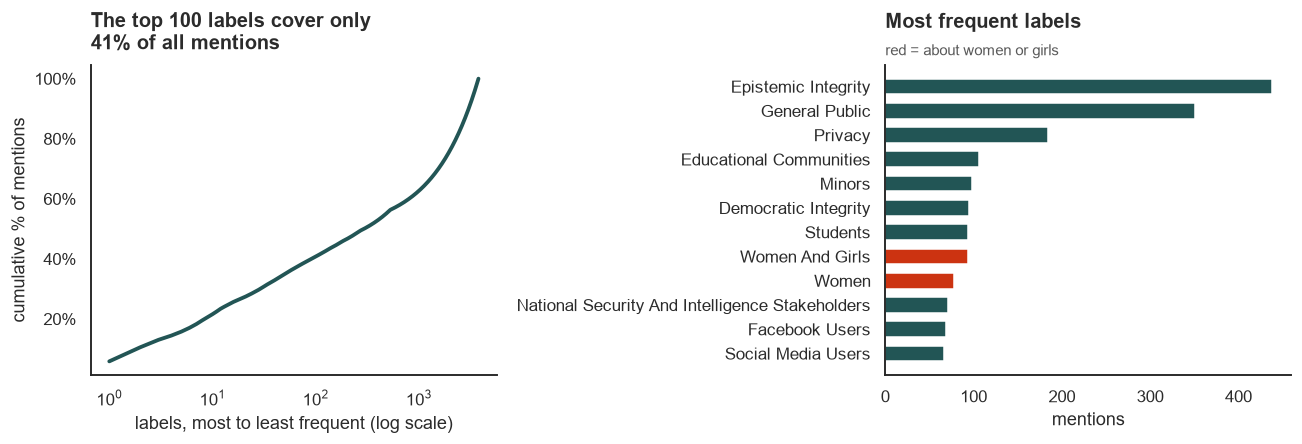

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

ax[0].plot(np.arange(1, len(cov) + 1), cov.values * 100, color=CMP_A, lw=2.5)
ax[0].set_xscale("log")
ax[0].yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax[0].set_xlabel("labels, most to least frequent (log scale)")
ax[0].set_ylabel("cumulative % of mentions")
titles(ax[0], f"The top 100 labels cover only\n{cov.iloc[99]:.0%} of all mentions")

top = vc.head(12)[::-1]
ax[1].barh(top.index, top.values, color=[HIGHLIGHT if t in women.index else CMP_A for t in top.index], height=0.65)
ax[1].set_xlabel("mentions")
titles(ax[1], "Most frequent labels", "red = about women or girls")

fig.tight_layout()
save(fig, "00b_harmed_fragmentation")
plt.show()

With labels this short and this rare, a topic model alone does not give clean groups. We first group the labels with **keyword rules**, which are easy to read and check. A label can match several groups. *General public* is only used when nothing more specific fits, and harms to values ("Epistemic Integrity", "Privacy") get their own group because they are not people.

In [25]:
GROUP_RULES = {
    "Women and girls": r"\bwom[ae]n\b|\bgirls?\b|\bfemale",
    "Children, parents, students, teachers": r"minor|child|\bkids?\b|teen|adolescen|student|school|youth|underage|pupil|educat|teacher|parent|famil",
    "Social media / platform users": r"social media|facebook|instagram|twitter|tiktok|youtube|\bx \(|whatsapp|reddit|snapchat|linkedin|telegram|meta users|google users|\bx users|\busers?\b|e?mail",
    "Chatbot / AI users": r"chatgpt|chatbot|openai|replika|character\.?ai|\bllm|\bai users|users of ai|ai agent|gemini|copilot|grok|claude|\bgpt",
    "Consumers and customers": r"consumer|customer|shopper|buyer|subscriber|tenant|borrower|applicant|tourist",
    "Patients and health": r"patient|health|mental|suicid|medical|vulnerable",
    "Workers and job seekers": r"worker|employee|job|driver|labou?r|candidate|staff|truck",
    "Professionals": r"researcher|scientist|developer|engineer|lawyer|attorney|professional|responder|firefighter|doctor|physician|nurse",
    "Creators and artists": r"artist|creator|author|writer|actor|musician|illustrator|copyright|performer|voice",
    "Racial, ethnic, LGBTQ+, disabled": r"of colou?r|black|african|asian|latin|hispanic|minorit|racial|ethnic|muslim|jewish|lgbt|gay|\btrans\b|indigenous|immigrant|disabilit|disabled|marginali|cisgender|queer|refugee|roma|romani|traveller|neurodivergent",
    "Public figures and journalists": r"public figure|celebrit|politic|president|trump|biden|journalis|\bmedia\b|news",
    "Voters and elections": r"voter|electorate|election|democra",
    "Victims of deepfakes, fraud, scams": r"deepfake|fraud|scam|victim|impersonat",
    "Data subjects (biometric, personal)": r"data subject|biometric|personal data",
    "Road users": r"\broad\b|pedestrian|passenger|cyclist|motorist|traffic",
    "Investors and finance": r"investor|bank|financial|elderly|retire",
    "Organisations and states": r"musk|publisher|law enforcement|compan|business|organi[sz]ation|government|institution|police|court|universit|agency|department|emergency services|military|national security|stakeholder|nation|^(bbc|google|tesla|anthropic|disney|waymo|arup|usaid|openai|microsoft)$",
}
GENERAL_PUBLIC = r"general public|\bpublic\b|citizen|society|\bpeople\b|everyone|resident|participants|communit|fans"
VALUES = r"integrity|privacy|trust|safety|security|rights|autonomy|dignity|equality|environment|freedom|reputation"

def label_groups(label):
    groups = [g for g, pattern in GROUP_RULES.items() if re.search(pattern, label, re.I)]
    if not groups and re.search(GENERAL_PUBLIC, label, re.I):
        groups = ["General public"]
    if not groups and re.search(VALUES, label, re.I):
        groups = ["Abstract values (not people)"]
    return groups

In [26]:
lab = pd.DataFrame({"label": vc.index, "mentions": vc.values})
lab["groups"] = lab["label"].map(label_groups)
lab["matched"] = lab["groups"].map(len) > 0

print(f"Keyword rules: {lab.matched.mean():.0%} of labels, "
      f"{lab.loc[lab.matched, 'mentions'].sum() / lab.mentions.sum():.0%} of mentions grouped")
print("Most frequent labels still without a group:")
lab.loc[~lab.matched, ["label", "mentions"]].head(15).set_index("label")

Keyword rules: 54% of labels, 74% of mentions grouped
Most frequent labels still without a group:


,mentions
label,
Kamala Harris,8
Ukraine,7
Cnn,6
Barack Obama,5
Taylor Swift,5
Targets Of Autonomous Ai Enabled Intrusion Operations,5
Albin Kurti,5
Volodymyr Zelenskyy,4
Universal Music Group,4


Most of what is left are **names of people, organisations and countries** ("Taylor Swift", "Universal Music Group", "Ukraine"), which no keyword list can cover. For these we use spaCy's named-entity model (`en_core_web_sm`): a label recognised as a person goes to *Named individuals*, an organisation or a label that is only a place name goes to *Organisations and states* (states = countries). A few well-known companies are missed by spaCy because the export writes them in title case ("Bbc"), so they are added by name to the keyword rule.

In [27]:
import spacy

nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])

label_to_groups = dict(zip(lab["label"], lab["groups"]))
unmatched = lab.loc[~lab.matched, "label"].tolist()
for label, doc in zip(unmatched, nlp.pipe(unmatched, batch_size=200)):
    kinds = {e.label_ for e in doc.ents}
    if "PERSON" in kinds:
        label_to_groups[label] = ["Named individuals"]
    elif "ORG" in kinds or (len(doc.ents) == 1 and doc.ents[0].text == label and doc.ents[0].label_ in ["GPE", "LOC"]):
        label_to_groups[label] = ["Organisations and states"]

lab["groups"] = lab["label"].map(label_to_groups)
lab["matched"] = lab["groups"].map(len) > 0
print(f"After spaCy: {lab.matched.mean():.0%} of labels, "
      f"{lab.loc[lab.matched, 'mentions'].sum() / lab.mentions.sum():.0%} of mentions grouped")

After spaCy: 86% of labels, 92% of mentions grouped


In [28]:
named = lab[lab["groups"].map(lambda g: g == ["Named individuals"])]
print(f"{len(named):,} labels tagged as named individuals. Random sample of 40 to check by hand:")
print(" | ".join(named["label"].sample(40, random_state=1)))

897 labels tagged as named individuals. Random sample of 40 to check by hand:
Gilberto Alcazar Lopez | Collien Fernandes | John Piscitella | Lee Ji Hye | Dennis Morida | Scarlett Johansson | Kelly Clarkson | Mary Franson | Kimberlee Williams | Ian Borg | Mcsweeny Synkar And Kachouroff Pllc | Shannon Carpenter | Claire Vo | Kate Garraway | Noa Kirel | Monica Geingos | Nijeer Parks | Steve Cohen | Albin Kurti | Mark A. Young | Paul Kagame | Bee Cups | Xiomara Castro | Rona Wang | Erik Rossiter | Mike Schmitz | Butler Snow | Monterrey Water And Drainage Services | Dumitru Alaiba | Gema | Ted Hui | Taylor Swift | Patrizio Bertelli | Bita Hemmati | Eric Horvitz | Marian Tofan | Jeff Koinange | Ivan Hristanov | Ciro Pellegrino | Jack Tame


**A manual check.** Reading the grouped labels showed one systematic gap: *Women Of Color* went only to the women group, and *People Of Color* fell into *General public*. We added "of color" to the racial rule. The two figures show the grouping before and after this fix.

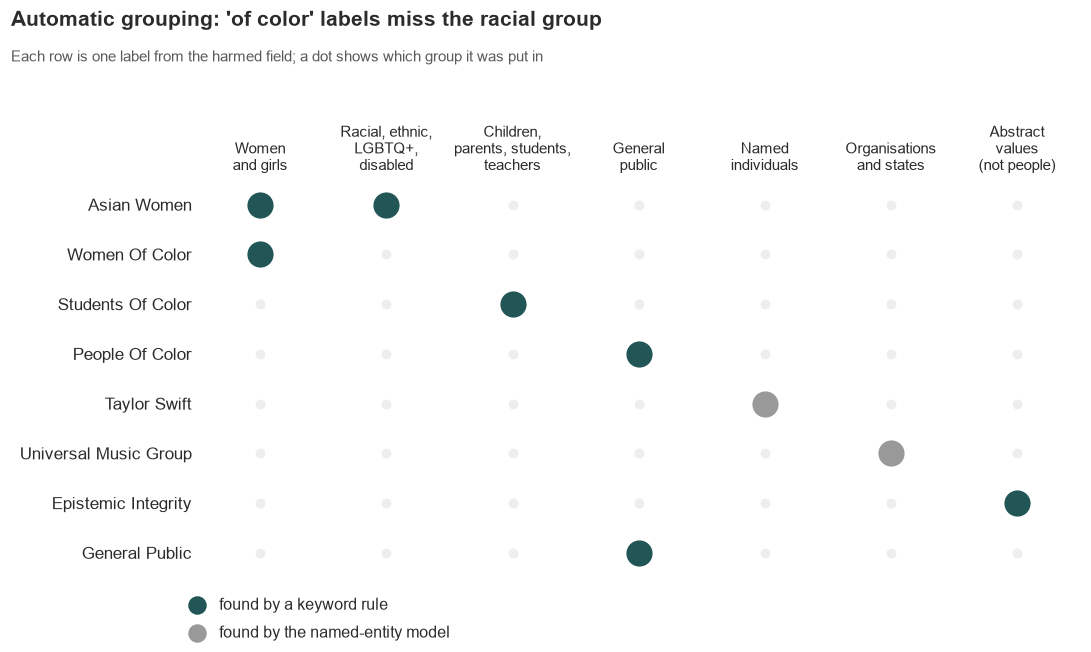

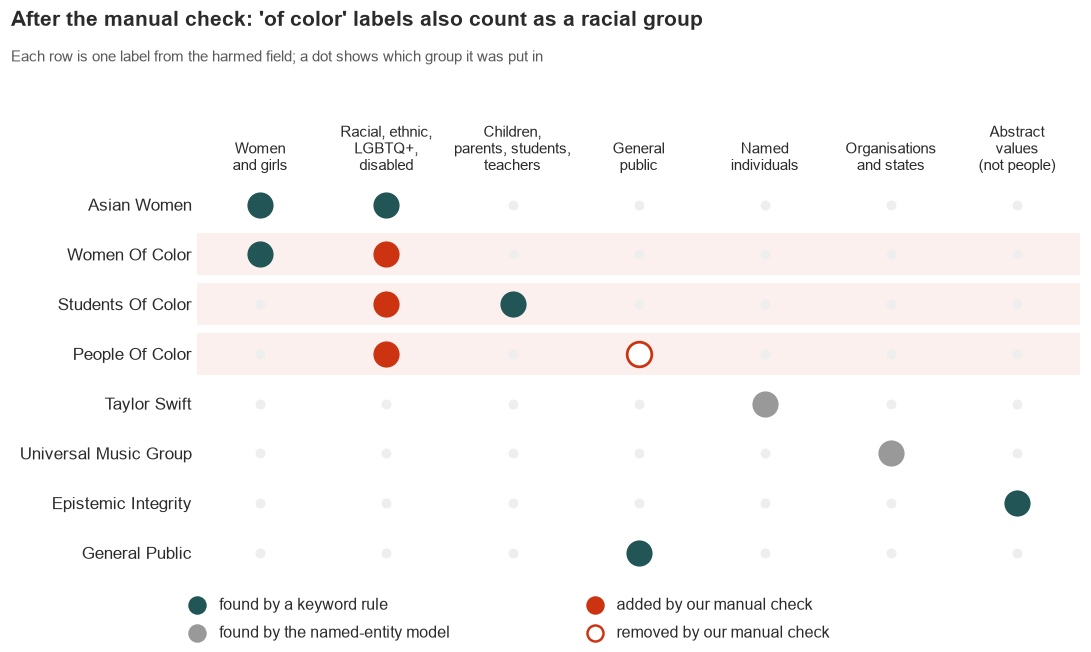

In [29]:
GROUPS = ["Women\nand girls", "Racial, ethnic,\nLGBTQ+,\ndisabled", "Children,\nparents, students,\nteachers",
          "General\npublic", "Named\nindividuals", "Organisations\nand states", "Abstract\nvalues\n(not people)"]
NER_COLOR = "#999999"

before = {"Asian Women":           [(0, "kw"), (1, "kw")],
          "Women Of Color":        [(0, "kw")],
          "Students Of Color":     [(2, "kw")],
          "People Of Color":       [(3, "kw")],
          "Taylor Swift":          [(4, "ner")],
          "Universal Music Group": [(5, "ner")],
          "Epistemic Integrity":   [(6, "kw")],
          "General Public":        [(3, "kw")]}
added = {"Women Of Color": [1], "Students Of Color": [1], "People Of Color": [1]}
removed = {"People Of Color": [3]}

def label_examples(after):
    rows = list(before)
    fig, ax = plt.subplots(figsize=(10, 6.2))
    for y, lab in enumerate(rows):
        ax.scatter(range(len(GROUPS)), [y] * len(GROUPS), s=30, color="#EEEEEE", zorder=1)
        if after and lab in added:
            ax.axhspan(y - 0.42, y + 0.42, color=HIGHLIGHT, alpha=0.07, lw=0, zorder=0)
        for g, how in before[lab]:
            if after and g in removed.get(lab, []):
                ax.scatter(g, y, s=260, facecolor="white", edgecolor=HIGHLIGHT, lw=1.8, zorder=2)
            else:
                ax.scatter(g, y, s=260, color=CMP_A if how == "kw" else NER_COLOR, zorder=2)
        if after:
            for g in added.get(lab, []):
                ax.scatter(g, y, s=260, color=HIGHLIGHT, zorder=2)

    ax.set_yticks(range(len(rows)), rows, fontsize=11)
    ax.set_ylim(len(rows) - 0.5, -0.5)
    ax.set_xticks(range(len(GROUPS)), GROUPS, fontsize=10)
    ax.xaxis.tick_top()
    ax.set_xlim(-0.5, len(GROUPS) - 0.5)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)

    keys = [(CMP_A, "found by a keyword rule", True), (NER_COLOR, "found by the named-entity model", True),
            (HIGHLIGHT, "added by our manual check", after), ("white", "removed by our manual check", after)]
    for i, (c, text, show) in enumerate(keys):
        x, y = [0.0, 0.0, 0.45, 0.45][i], [-0.07, -0.14, -0.07, -0.14][i]
        a = 1 if show else 0
        ax.scatter(x, y, s=110, transform=ax.transAxes, clip_on=False, alpha=a,
                   facecolor=c, edgecolor=HIGHLIGHT if c == "white" else c, lw=1.6)
        ax.text(x + 0.025, y, text, transform=ax.transAxes, va="center", fontsize=10.5, alpha=a)

    if after:
        title = "After the manual check: 'of color' labels also count as a racial group"
    else:
        title = "Automatic grouping: 'of color' labels miss the racial group"
    fig.suptitle(title, x=0.01, ha="left", fontsize=14, fontweight="bold")
    fig.text(0.01, 0.905, "Each row is one label from the harmed field; a dot shows which group it was put in",
             fontsize=10, color="#5A5A5A")
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    return fig

for after in [False, True]:
    fig = label_examples(after)
    save(fig, f"00d_label_examples_{'after' if after else 'before'}")
    plt.show()

In [30]:
def incident_groups(labels):
    groups = sorted({g for t in labels for g in label_to_groups.get(t, [])})
    return groups if groups else ["Not grouped"]

inc_raw["harmed_groups"] = inc_raw["harmed_list"].map(incident_groups)
grouped = inc_raw["harmed_groups"].map(lambda g: g != ["Not grouped"])

pd.DataFrame({"grouped %": [lab.matched.mean() * 100,
                            lab.loc[lab.matched, "mentions"].sum() / lab.mentions.sum() * 100,
                            grouped.mean() * 100]},
             index=["labels", "mentions", "incidents"]).round(0)

,grouped %
labels,86.0
mentions,92.0
incidents,97.0


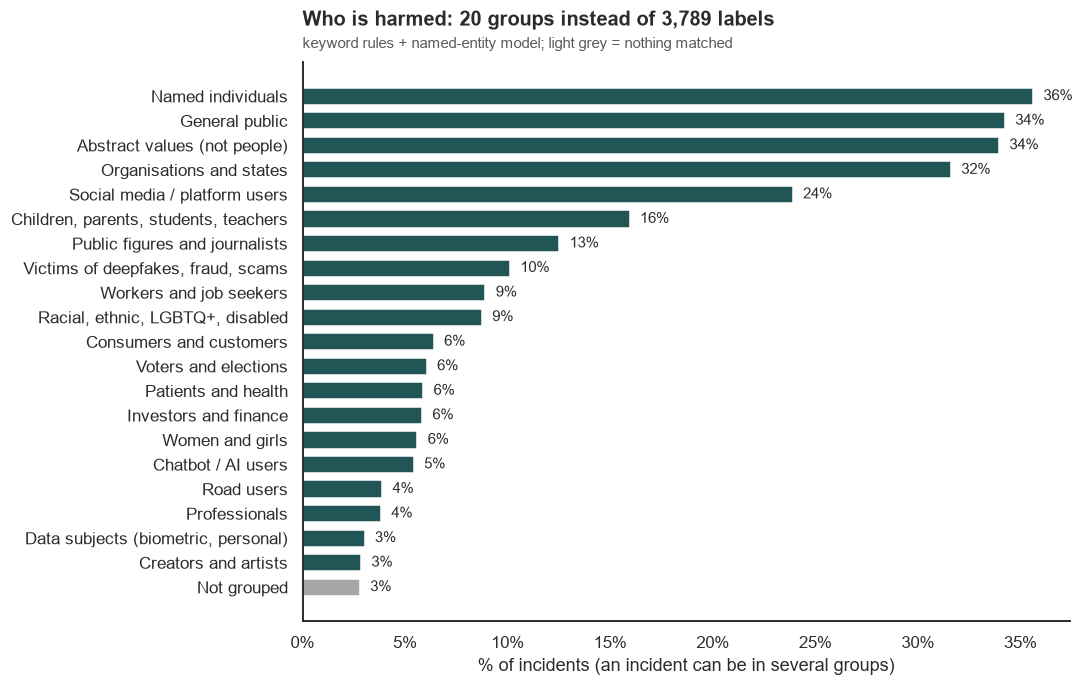

In [31]:
share = (inc_raw["harmed_groups"].explode().value_counts() / len(inc_raw) * 100).sort_values()

fig, ax = plt.subplots(figsize=(9, 6.6))
ax.barh(share.index, share.values, color=[CMP_B if g == "Not grouped" else CMP_A for g in share.index], height=0.7)
for y, v in enumerate(share.values):
    ax.text(v + 0.5, y, f"{v:.0f}%", va="center", fontsize=10)
ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax.set_xlabel("% of incidents (an incident can be in several groups)")
titles(ax, f"Who is harmed: {share.size - 1} groups instead of {len(lab):,} labels",
       "keyword rules + named-entity model; light grey = nothing matched")
save(fig, "00d_harmed_groups")
plt.show()

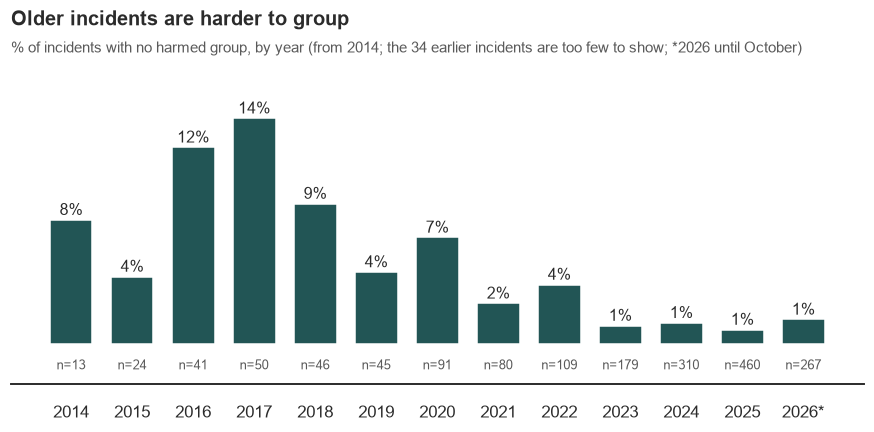

In [32]:
year = inc_raw["year"]
by_year = (~grouped).groupby(year).agg(["mean", "size"]).loc[2014:]
by_year.index = by_year.index.astype(int)
n_early = (year < 2014).sum()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(by_year.index, by_year["mean"] * 100, color=CMP_A, width=0.7)
for yr, p, n in zip(by_year.index, by_year["mean"] * 100, by_year["size"]):
    ax.text(yr, p + 0.3, f"{p:.0f}%", ha="center", fontsize=10.5)
    ax.text(yr, -1.6, f"n={n}", ha="center", fontsize=8.5, color="#5A5A5A")
ax.set_xticks(by_year.index, [f"{y}*" if y == 2026 else str(y) for y in by_year.index])
ax.set_ylim(-2.5, by_year["mean"].max() * 100 * 1.25)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.tick_params(axis="x", length=0, pad=14)
titles(ax, "Older incidents are harder to group",
       f"% of incidents with no harmed group, by year (from 2014; the {n_early} earlier incidents are too few to show; *2026 until October)")
save(fig, "00e_not_grouped_by_year")
plt.show()

The grouping works better on recent incidents, probably because newer labels follow more standard wording. Comparisons of harmed groups across periods are therefore slightly biased towards the recent years.

#### Topic model of the harmed field

As a check of the keyword groups we also fit a topic model (NMF on TF-IDF) to the harmed text of each incident. Person names are too rare to be picked up as words, so labels tagged as *Named individuals* are first replaced by the token `namedperson`.

There is no single correct number of topics *k*, so we compare several values on three measures: **coherence** (do the top words of a topic appear together?), **stability** (do different random starts give the same topics?) and **agreement with the keyword groups**.

In [33]:
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import normalized_mutual_info_score

def harmed_text(labels):
    words = ["namedperson" if label_to_groups.get(t) == ["Named individuals"] else t for t in labels]
    return " ; ".join(t for t in words if t != "Unknown")

h_text = inc_raw["harmed_list"].map(harmed_text)
h_text = h_text[h_text != ""]

vec = TfidfVectorizer(stop_words="english", min_df=3, max_df=0.5, sublinear_tf=True)
Xh = vec.fit_transform(h_text)
B = CountVectorizer(vocabulary=vec.vocabulary_, binary=True).fit_transform(h_text)
print(f"{Xh.shape[0]:,} incidents, {Xh.shape[1]} words")

1,744 incidents, 629 words


In [34]:
def umass(top_words, B):
    co = (B.T @ B).toarray()
    scores = [np.log((co[w[m], w[l]] + 1) / co[w[l], w[l]])
              for w in top_words for m in range(1, len(w)) for l in range(m)]
    return np.mean(scores)

group_rank = {g: i for i, g in enumerate(share.sort_values(ascending=False).index)}
rule_label = inc_raw.loc[h_text.index, "harmed_groups"].map(lambda g: min(g, key=group_rank.get))

rows = []
for k in [4, 6, 8, 10, 12, 15, 20, 25]:
    fits = [NMF(k, init="random", random_state=s, max_iter=400).fit(Xh) for s in range(4)]
    assign = [f.transform(Xh).argmax(axis=1) for f in fits]
    top_words = np.argsort(-fits[0].components_, axis=1)[:, :8]
    rows.append({"k": k,
                 "coherence": umass(top_words, B),
                 "stability": np.mean([normalized_mutual_info_score(assign[i], assign[j])
                                       for i in range(4) for j in range(i + 1, 4)]),
                 "agreement with keyword groups": normalized_mutual_info_score(rule_label, assign[0])})
sel = pd.DataFrame(rows).set_index("k")
sel.round(3)

,coherence,stability,agreement with keyword groups
k,,,
4,-2.108,0.870,0.290
6,-2.221,0.772,0.261
8,-2.307,0.799,0.262
10,-2.305,0.736,0.274
12,-2.377,0.742,0.272
15,-2.334,0.708,0.280
20,-2.319,0.675,0.274
25,-2.284,0.702,0.272


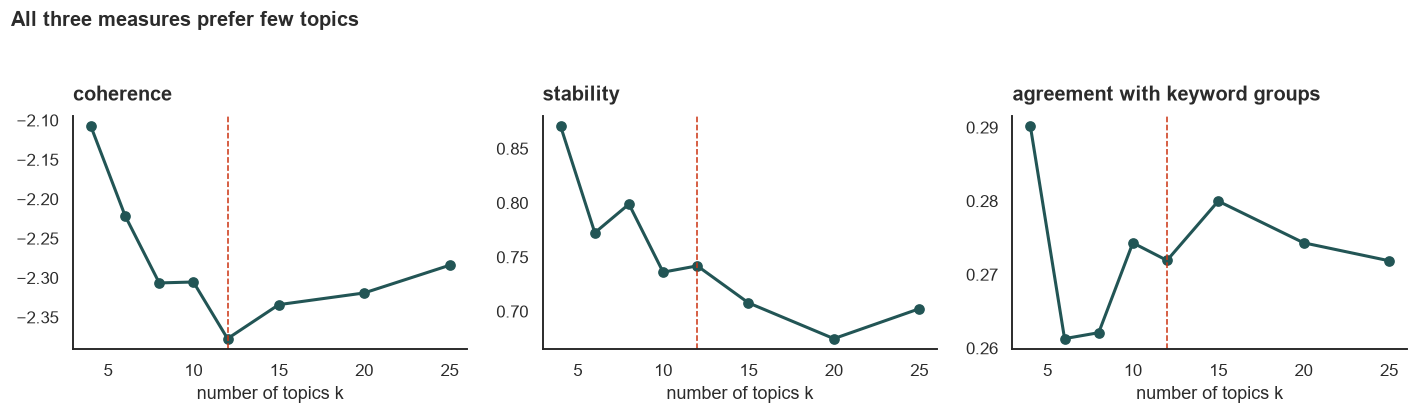

In [35]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, col in zip(ax, sel.columns):
    a.plot(sel.index, sel[col], marker="o", color=CMP_A, lw=2)
    a.axvline(12, color=HIGHLIGHT, lw=1, ls="--")
    a.set_xlabel("number of topics k")
    titles(a, col)
fig.suptitle("All three measures prefer few topics", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.04)
fig.tight_layout()
save(fig, "00c_choose_k")
plt.show()

All three measures are best at k = 4, which is expected, but 4 topics are far too coarse for 20 harmed groups. From k = 8 upwards the curves are almost flat, so they don't pick a winner. We use **k = 12** because there most topics clearly match one keyword group. This is a judgment call, not an optimum.

In [36]:
K = 12
nmf_h = NMF(K, init="nndsvd", random_state=SEED, max_iter=500).fit(Xh)
topic = pd.Series(nmf_h.transform(Xh).argmax(axis=1), index=h_text.index)
inc_raw["harmed_topic"] = topic
voc = vec.get_feature_names_out()

pairs = pd.DataFrame({"topic": topic, "group": inc_raw.loc[h_text.index, "harmed_groups"]}).explode("group")
size = topic.value_counts()
main_group = pairs.groupby("topic")["group"].agg(lambda s: s.value_counts().index[0])
main_share = pairs.groupby("topic")["group"].agg(lambda s: s.value_counts().iloc[0]) / size * 100

topics = pd.DataFrame({"top words": [", ".join(voc[np.argsort(-nmf_h.components_[k])[:6]]) for k in range(K)],
                       "incidents": size,
                       "main keyword group": main_group,
                       "% in main group": main_share.round(0)}).sort_values("incidents", ascending=False)
topics

,top words,incidents,main keyword group,% in main group
2,"users, facebook, social, media, instagram, twi...",284,Social media / platform users,95.0
1,"general, public, investors, india, australia, ...",277,General public,95.0
0,"namedperson, family, investors, fans, employee...",214,Named individuals,86.0
3,"integrity, epistemic, democratic, voters, judi...",155,Abstract values (not people),75.0
5,"students, educational, communities, school, mi...",138,"Children, parents, students, teachers",83.0
4,"women, girls, victims, abuse, deepfake, non",126,"Victims of deepfakes, fraud, scams",73.0
11,"privacy, data, biometric, subjects, ai, patients",122,Abstract values (not people),69.0
6,"people, black, seeking, medical, advice, jewish",116,General public,57.0
10,"security, national, stakeholders, intelligence...",112,Organisations and states,90.0
8,"drivers, tesla, road, uber, amazon, motorists",92,Workers and job seekers,63.0


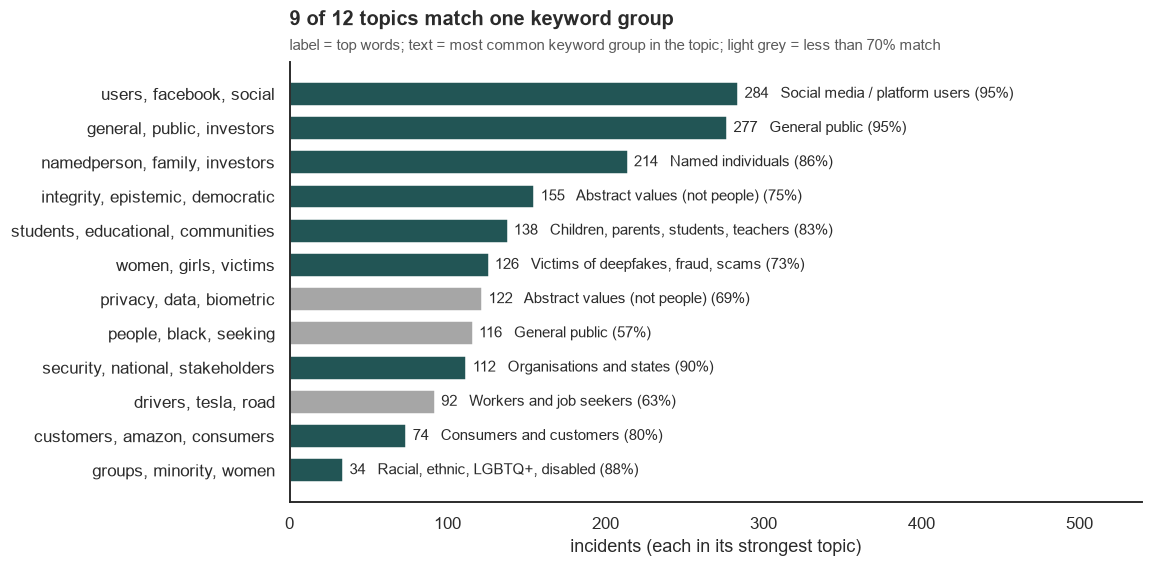

In [37]:
t = topics.iloc[::-1]
labels = [", ".join(w.split(", ")[:3]) for w in t["top words"]]

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(labels, t["incidents"], color=[CMP_A if p >= 70 else CMP_B for p in t["% in main group"]], height=0.7)
for y, (n, g, p) in enumerate(zip(t["incidents"], t["main keyword group"], t["% in main group"])):
    ax.text(n + 4, y, f"{n}   {g} ({p:.0f}%)", va="center", fontsize=9.5)
ax.set_xlim(0, t["incidents"].max() * 1.9)
ax.set_xlabel("incidents (each in its strongest topic)")
titles(ax, f"{(t['% in main group'] >= 70).sum()} of {K} topics match one keyword group",
       "label = top words; text = most common keyword group in the topic; light grey = less than 70% match")
save(fig, "00f_harmed_topics")
plt.show()

The topic model and the keyword groups mostly agree, which supports the keyword grouping. With the `namedperson` token the model now finds a topic for named individuals as well (about 210 incidents). It also shows that harm to **women and girls** sits together with deepfake abuse in one topic. The weaker topics (*people, black, medical ...*) mix several small groups.

### 2.7 Editor notes

30% of incidents have an editor note. Before using all incidents we check whether the notes flag problems, e.g. an incident that is a duplicate or should not be in the database.

In [38]:
notes = inc_raw["Editor Notes"].dropna()
checks = {"timeline / dates": r"timeline|date",
          "refers to another incident": r"see also|incident \d+",
          "duplicate": r"duplicat",
          "should be an issue, not an incident": r"reclassification as an issue|migrated to issue"}
display(pd.Series({k: notes.str.contains(p, case=False).sum() for k, p in checks.items()}).to_frame("notes"))

flagged = inc_raw["Editor Notes"].str.contains(checks["should be an issue, not an incident"], case=False, na=False) \
          | inc_raw["title"].str.contains("migrated to issue", case=False)
inc_raw.loc[flagged, ["Incident ID", "year", "title", "Editor Notes"]]

,notes
timeline / dates,359
refers to another incident,151
duplicate,1
"should be an issue, not an incident",2


,Incident ID,year,title,Editor Notes
20,21,2016,Tougher Turing Test Exposes Chatbots’ Stupidit...,NaN
246,252,2022,Remotely Operated Taser-Armed Drones Proposed ...,This incident ID should be reviewed for possib...
455,466,2023,AI-Generated Text Detectors Reportedly Misclas...,This record should be reviewed for possible re...


The notes are mostly timelines and links to related incidents. The one "duplicate" is about a duplicate licence plate, not a duplicate incident. Three incidents are flagged as possibly not real incidents: one was already moved to an "issue" by the editors (its title says *migrated to Issue*), two are only marked for review. We drop the migrated one and keep the other two, since the editors have not decided yet. This is 3 out of 1,749 incidents, so it does not change any result.

In [39]:
inc_raw = inc_raw[~inc_raw["title"].str.contains("migrated to issue", case=False)].copy()
print(f"{len(inc_raw):,} incidents left")

1,748 incidents left


### 2.8 Incident text

For the topic models, each incident is described by its title and description. A quick check of length, empty texts and duplicates:

In [40]:
text = inc_raw["title"].fillna("") + ". " + inc_raw["description"].fillna("")
words = text.str.split().str.len()

print("Empty texts:", (inc_raw["description"].fillna("").str.strip() == "").sum())
print("Duplicate titles:", inc_raw["title"].duplicated().sum(), "| duplicate descriptions:", inc_raw["description"].duplicated().sum())
print(f"Words per incident: median {words.median():.0f}, min {words.min()}, max {words.max()}")
inc_raw.loc[words < 20, ["Incident ID", "year", "description"]]

Empty texts: 0
Duplicate titles: 0 | duplicate descriptions: 0
Words per incident: median 68, min 10, max 119


,Incident ID,year,description
13,14,2017,Google Cloud's Natural Language API provided r...
15,16,2015,Google Photos image processing software mistak...
18,19,2013,Advertisements chosen by Google Adsense are re...
25,26,2017,Vietnamese security firm Bkav created an impro...
38,39,2017,University of Washington researchers made a de...
44,45,2011,Google's autocomplete feature alongside its im...
59,60,2017,FaceApp is criticized for offering racist filt...
86,87,2020,UK passport photo checker shows bias against d...
122,125,2020,Amazon’s robotic fulfillment centers have high...


Every incident has a text, there are no duplicates, and the texts are short and similar in length, because the editors write them in a fixed style. The few very short ones are old incidents; they are kept.

### 2.9 Final incident table

All decisions from this section in one place: shorter column names, the seven risk domains, intent without *Other*, the four periods and one text column for the models.

In [41]:
inc = inc_raw.rename(columns={"Incident ID": "id", "Risk Domain": "domain_raw", "Risk Subdomain": "subdomain",
                              "Sector of Deployment": "sector"}).copy()

inc["domain"] = pd.Categorical(inc["domain_raw"].map(DOMAIN_MAP), categories=DOMAINS)
inc["classified"] = inc["domain"].notna()
inc["dom_label"] = inc["domain"].astype(object).fillna("Unclassified")
inc["intent_s"] = inc["Intent"].where(inc["Intent"].isin(INTENTS))
inc["period"] = pd.cut(inc["year"], [0, 2018, 2022, 2024, 2026], labels=PERIODS)
inc["text"] = inc["title"] + ". " + inc["description"]

print(f"{len(inc):,} incidents, {inc['classified'].sum():,} with a risk domain ({inc['classified'].mean():.0%})")
inc["dom_label"].value_counts().to_frame("incidents").T

1,748 incidents, 1,495 with a risk domain (86%)


dom_label,Malicious use,System failures,Unclassified,Discrimination & toxicity,Misinformation,Privacy & security,Human-computer interaction,Socioeconomic & environmental
incidents,566,312,253,243,196,112,42,24


## 3. What can we trust? Coverage of the classifications

Besides the basic fields, the AIID has three classification layers. The MIT risk taxonomy covers most incidents, CSET and GMF only a small part, so the analysis is built on MIT. The newest incidents are often not classified yet.

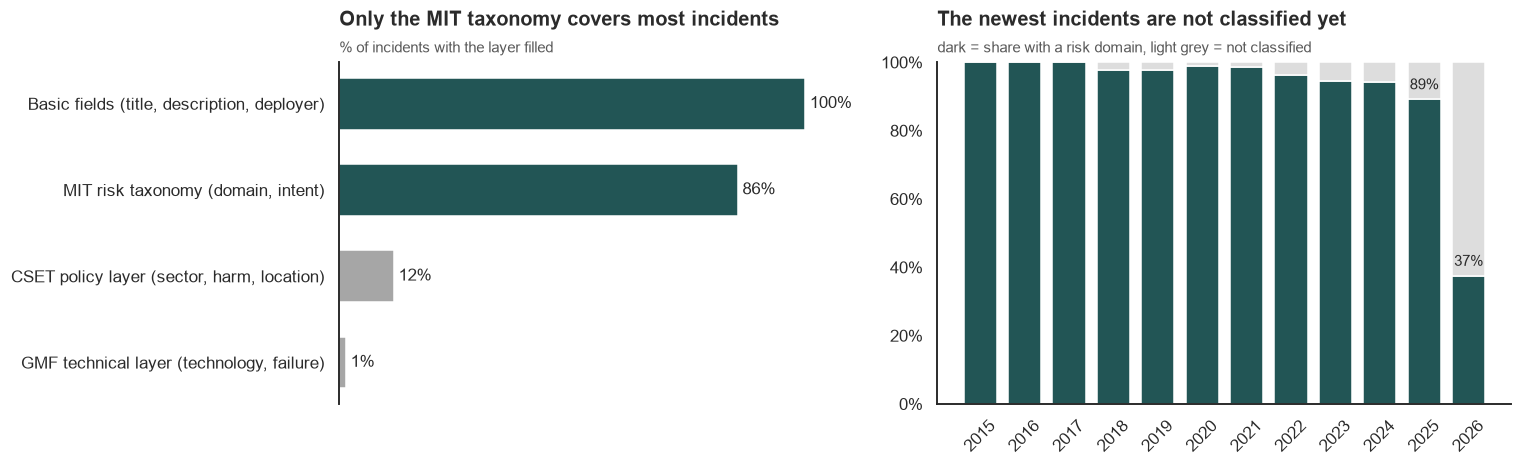

In [42]:
layers = pd.Series({"Basic fields (title, description, deployer)": inc["description"].notna().mean(),
                    "MIT risk taxonomy (domain, intent)": inc["classified"].mean(),
                    "CSET policy layer (sector, harm, location)": inc["sector"].notna().mean(),
                    "GMF technical layer (technology, failure)": inc["AI Technology"].notna().mean()}) * 100
by_year = inc[inc["year"] >= 2015].groupby("year")["classified"].mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 1.1]})

ax[0].barh(layers.index[::-1], layers.values[::-1], color=[CMP_A if v > 50 else CMP_B for v in layers.values[::-1]], height=0.6)
for y, v in enumerate(layers.values[::-1]):
    ax[0].text(v + 1, y, f"{v:.0f}%", va="center", fontsize=11)
ax[0].set_xlim(0, 112)
ax[0].set_xticks([])
ax[0].spines["bottom"].set_visible(False)
titles(ax[0], "Only the MIT taxonomy covers most incidents", "% of incidents with the layer filled")

ax[1].bar(by_year.index, by_year.values, color=CMP_A, width=0.75)
ax[1].bar(by_year.index, 100 - by_year.values, bottom=by_year.values, color=DOM_COLOR["Unclassified"], width=0.75)
for x in [2025, 2026]:
    ax[1].text(x, by_year[x] + 2, f"{by_year[x]:.0f}%", ha="center", va="bottom", fontsize=10)
ax[1].set_xticks(by_year.index)
ax[1].tick_params(axis="x", labelrotation=45)
ax[1].set_ylim(0, 100)
ax[1].yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
titles(ax[1], "The newest incidents are not classified yet", "dark = share with a risk domain, light grey = not classified")

fig.tight_layout()
save(fig, "01_coverage")
plt.show()

## 4. The big picture: how many incidents, and of what kind?

### 4.1 Incidents per year

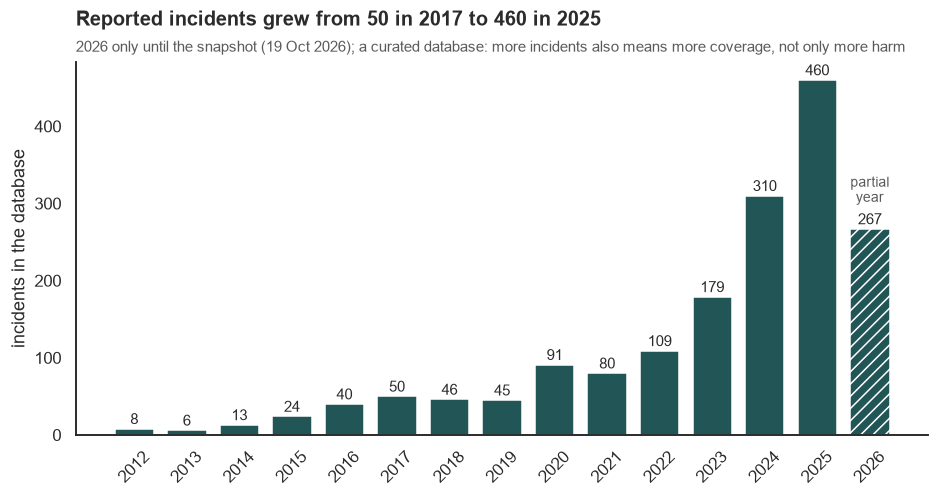

In [43]:
per_year = inc[inc["year"] >= 2012].groupby("year").size()

fig, ax = plt.subplots(figsize=(10, 4.4))
bars = ax.bar(per_year.index, per_year.values, color=CMP_A, width=0.75)
bars[-1].set_hatch("///")
bars[-1].set_edgecolor("white")
for x, v in per_year.items():
    ax.text(x, v + 6, f"{v}", ha="center", fontsize=9.5)
ax.text(2026, per_year[2026] + 35, "partial\nyear", ha="center", fontsize=9, color="#5A5A5A")
ax.set_xticks(per_year.index)
ax.tick_params(axis="x", labelrotation=45)
ax.set_ylabel("incidents in the database")
titles(ax, f"Reported incidents grew from {per_year[2017]} in 2017 to {per_year[2025]} in 2025",
       f"2026 only until the snapshot ({SNAPSHOT}); a curated database: more incidents also means more coverage, not only more harm")
save(fig, "02_incidents_per_year")
plt.show()

### 4.2 Types of harm over time

In [44]:
counts = pd.crosstab(inc["year"], inc["dom_label"]).reindex(columns=DOMAINS + ["Unclassified"], fill_value=0).loc[2015:]
shares = pd.crosstab(inc["period"], inc["domain"], normalize="index").reindex(columns=DOMAINS) * 100
n_period = inc[inc["classified"]].groupby("period", observed=True).size()
shares

domain,Malicious use,System failures,Discrimination & toxicity,Misinformation,Privacy & security,Human-computer interaction,Socioeconomic & environmental
period,,,,,,,
up to 2018,5.825243,43.203883,33.009709,1.941748,10.679612,0.970874,4.368932
2019-22,15.094340,35.849057,28.616352,6.918239,8.176101,3.773585,1.572327
2023-24,47.722343,12.798265,11.713666,18.655098,6.290672,1.952278,0.867679
2025-26,56.078431,9.803922,5.882353,16.470588,6.862745,3.725490,1.176471


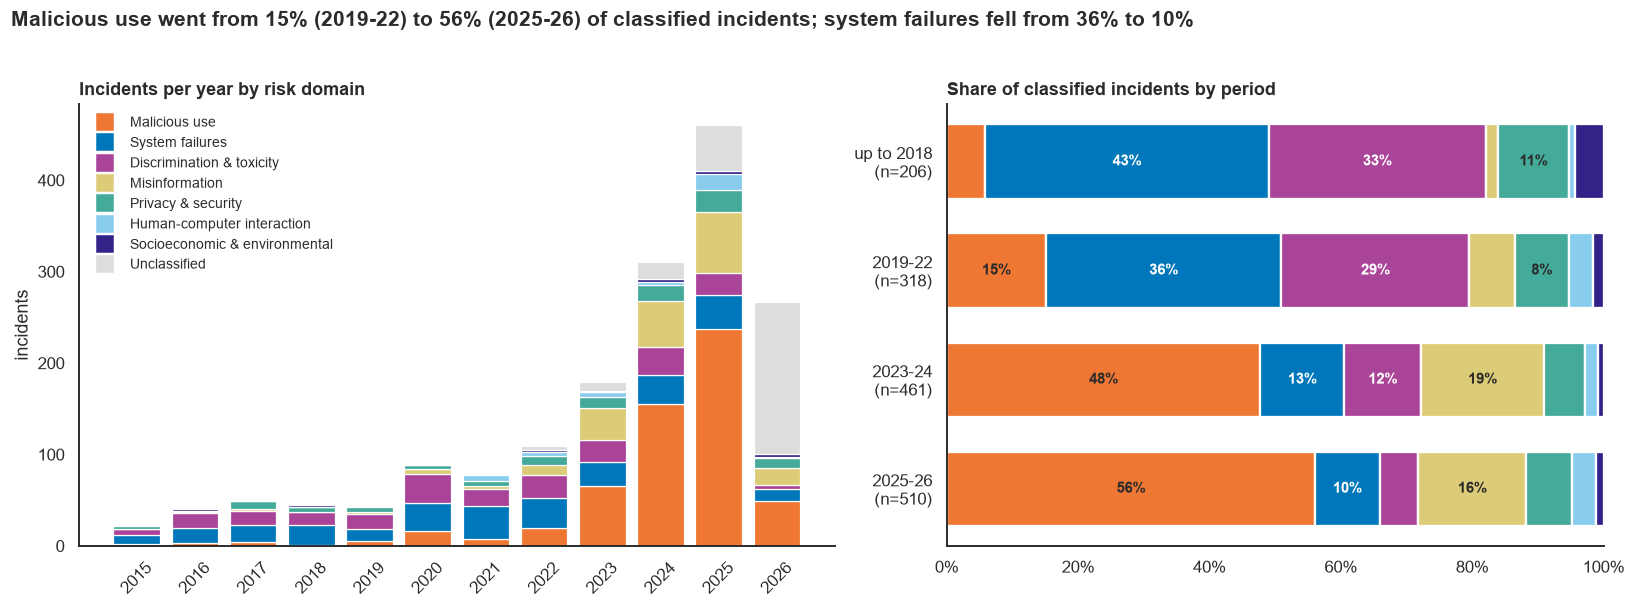

In [45]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.15, 1]})

bottom = np.zeros(len(counts))
for d in DOMAINS + ["Unclassified"]:
    ax[0].bar(counts.index, counts[d], bottom=bottom, color=DOM_COLOR[d], width=0.8, edgecolor="white", linewidth=0.8)
    bottom += counts[d].values
ax[0].set_xticks(counts.index)
ax[0].tick_params(axis="x", labelrotation=45)
ax[0].set_ylabel("incidents")
ax[0].set_title("Incidents per year by risk domain", fontsize=12)
domain_legend(ax[0], loc="upper left", fontsize=9)

y = np.arange(len(shares))[::-1]
left = np.zeros(len(shares))
for d in DOMAINS:
    ax[1].barh(y, shares[d], left=left, color=DOM_COLOR[d], height=0.68, edgecolor="white", linewidth=1.5)
    for yi, l, v in zip(y, left, shares[d]):
        if v >= 7:
            ax[1].text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=9.5, fontweight="bold",
                       color=INK if d in DARK_TEXT else "white")
    left += shares[d].values
ax[1].set_yticks(y, [f"{p}\n(n={n_period[p]})" for p in shares.index])
ax[1].set_xlim(0, 100)
ax[1].xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax[1].set_title("Share of classified incidents by period", fontsize=12)

first, last = shares.index[1], shares.index[-1]
fig.suptitle(f"Malicious use went from {shares.loc[first, 'Malicious use']:.0f}% ({first}) to {shares.loc[last, 'Malicious use']:.0f}% ({last}) "
             f"of classified incidents; system failures fell from {shares.loc[first, 'System failures']:.0f}% to {shares.loc[last, 'System failures']:.0f}%",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.02)
fig.tight_layout()
save(fig, "03_domains_over_time")
plt.show()

Left: incidents per year split by risk domain (grey = not classified yet). Right: the share of each domain among the **classified** incidents of each period, so that the unclassified backlog of 2025-26 does not distort the shares.

### 4.3 Intentional or accidental?

The MIT taxonomy also records whether the harm was intended. Below is the share of intentional incidents and of malicious use **per year with a 95% confidence interval** (Wilson interval, which works better than the normal one for small samples), only for years with at least 15 classified incidents.

In [46]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

def share_by_year(flag, min_n=15):
    g = flag.dropna().astype(float).groupby(inc["year"]).agg(["sum", "count"])
    g = g[(g.index >= 2015) & (g["count"] >= min_n)]
    g["p"] = g["sum"] / g["count"]
    g["lower bound"], g["upper bound"] = wilson(g["sum"], g["count"])
    return g

intent_trend = share_by_year((inc["intent_s"] == "Intentional").where(inc["intent_s"].notna()))
misuse_trend = share_by_year((inc["domain"] == "Malicious use").where(inc["classified"]))
intent_trend.round(2)

,sum,count,p,lower bound,upper bound
year,,,,,
2015,5.0,24,0.21,0.09,0.40
2016,9.0,40,0.22,0.12,0.38
2017,12.0,49,0.24,0.15,0.38
2018,10.0,45,0.22,0.13,0.36
2019,13.0,43,0.30,0.19,0.45
2020,23.0,88,0.26,0.18,0.36
2021,18.0,78,0.23,0.15,0.34
2022,40.0,105,0.38,0.29,0.48
2023,89.0,168,0.53,0.45,0.60


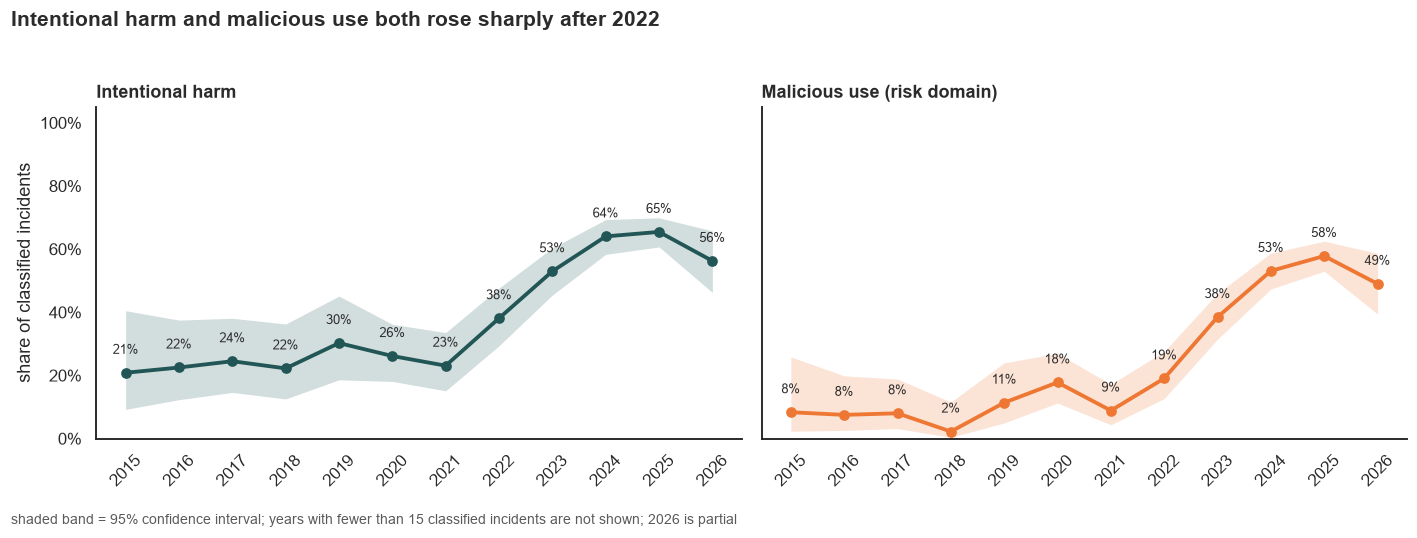

In [47]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for a, d, color, name in [(ax[0], intent_trend, CMP_A, "Intentional harm"),
                          (ax[1], misuse_trend, DOM_COLOR["Malicious use"], "Malicious use (risk domain)")]:
    a.fill_between(d.index, d["lower bound"], d["upper bound"], color=color, alpha=0.2, linewidth=0)
    a.plot(d.index, d["p"], color=color, lw=2.5, marker="o")
    for x, v in d["p"].items():
        a.text(x, v + 0.06, f"{v:.0%}", ha="center", fontsize=8.5)
    a.set_xticks(d.index)
    a.tick_params(axis="x", labelrotation=45)
    a.set_ylim(0, 1.05)
    a.set_title(name, fontsize=12)
ax[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax[0].set_ylabel("share of classified incidents")
fig.suptitle("Intentional harm and malicious use both rose sharply after 2022", x=0.01, ha="left",
             fontsize=13.5, fontweight="bold", y=1.03)
fig.text(0.01, -0.03, "shaded band = 95% confidence interval; years with fewer than 15 classified incidents are not shown; 2026 is partial",
         fontsize=9, color="#5A5A5A")
fig.tight_layout()
save(fig, "04_intent_misuse_trend")
plt.show()

### 4.4 Which kinds of harm sit behind the shift?

The subdomains show what the harm is. Each cell is the share of that subdomain among the classified incidents of the period; the coloured square shows the risk domain it belongs to.

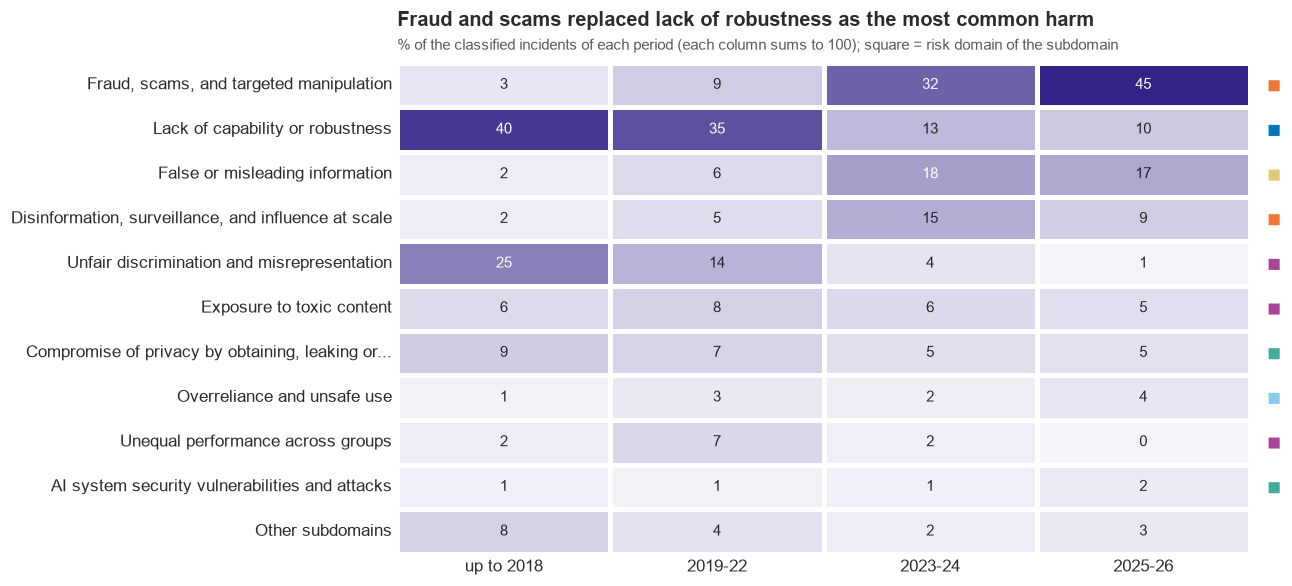

In [48]:
top_sub = inc["subdomain"].value_counts().head(10).index
heat = (pd.crosstab(inc["subdomain"], inc["period"], normalize="columns") * 100).loc[top_sub]
heat.loc["Other subdomains"] = 100 - heat.sum()
dom_of = inc.dropna(subset=["subdomain"]).groupby("subdomain")["dom_label"].agg(lambda s: s.mode()[0])

fig, ax = plt.subplots(figsize=(10, 5.8))
sns.heatmap(heat, annot=True, fmt=".0f", cmap=SEQ, cbar=False, ax=ax, linewidths=2, linecolor="white",
            yticklabels=[textwrap.shorten(s, 55, placeholder="...") for s in heat.index], annot_kws={"fontsize": 10})
for i, s in enumerate(heat.index):
    if s in dom_of:
        ax.text(len(heat.columns) + 0.08, i + 0.5, "■", color=DOM_COLOR[dom_of[s]], fontsize=16, va="center")
ax.tick_params(length=0)
ax.set_xlabel("")
ax.set_ylabel("")
titles(ax, "Fraud and scams replaced lack of robustness as the most common harm",
       "% of the classified incidents of each period (each column sums to 100); square = risk domain of the subdomain")
save(fig, "05_subdomain_heatmap")
plt.show()

## 5. Who deploys, who builds, who is harmed?

### 5.1 Named organisations and generic actors

The deployer and developer fields mix two kinds of names: real organisations (*Meta*, *OpenAI*, *Tesla*) and generic descriptions of actors (*Scammers*, *Deepfake Technology Developers*). Counting them together would compare things that are not comparable.

In [49]:
for col in ["deployer_list", "developer_list"]:
    top = inc[col].explode().value_counts().head(12)
    print(f"{col}: " + ", ".join(f"{k} ({v})" for k, v in top.items()))

deployer_list: Scammers (238), Unknown actor (181), Deepfake Creators (124), Synthetic Media Creators (98), Meta (92), Openai (82), Information Manipulation Actors (73), Google (63), Tesla (43), Law Enforcement (40), Cybercriminals (39), Microsoft (30)
developer_list: Deepfake Technology Developers (448), Synthetic Audio Generation Technology Developers (238), Openai (190), Large Language Model Developers (133), Synthetic Media Generation Technology Developers (128), Synthetic Image Generation Technology Developers (122), Unknown actor (113), Meta (98), Google (97), Chatbot Developers (69), Generative Ai Developers (66), Synthetic Video Generation Technology Developers (53)


The most frequent deployers and developers are generic actors, not companies. We mark a name as **generic** when it describes a type of actor (a plural like *Scammers*, *Developers*, *Users*, or *Unknown actor*) and as **named** otherwise.

In [50]:
GENERIC = (r"\b(developers|deployers|creators|actors|scammers|spreaders|cybercriminals|criminals|fraudsters|hackers|"
           r"operators|users|students|boys|men|women|minors|lawyers|law firms|stalkers|perpetrators|departments|"
           r"enforcement|individuals|people|groups|companies|platforms|employers|attackers|accounts|teenagers|parents)\b"
           r"|technology$|^unknown actor$")

def actor_kind(name):
    return "generic" if re.search(GENERIC, name, re.I) else "named"

actors = pd.concat([inc["deployer_list"].explode(), inc["developer_list"].explode()]).dropna()
kinds = actors.map(actor_kind)
for k in ["named", "generic"]:
    top = actors[kinds == k].value_counts().head(15)
    print(f"{k} ({(kinds == k).mean():.0%} of mentions): " + ", ".join(top.index))

named (55% of mentions): Openai, Meta, Google, Tesla, Microsoft, Amazon, Xai, Anthropic, Waymo, X (Twitter), Apple, Youtube, Tiktok, Cruise, Instagram
generic (45% of mentions): Deepfake Technology Developers, Unknown actor, Synthetic Audio Generation Technology Developers, Scammers, Deepfake Creators, Large Language Model Developers, Synthetic Media Generation Technology Developers, Synthetic Image Generation Technology Developers, Synthetic Media Creators, Information Manipulation Actors, Chatbot Developers, Generative Ai Developers, Synthetic Video Generation Technology Developers, Law Enforcement, Cybercriminals


The split works well for the frequent names. A few edge cases remain (e.g. *Government Of Russia* counts as named, *Law Enforcement* as generic), which is fine for our purpose.

### 5.2 From companies to anonymous actors

For every incident we ask two separate questions: is any **real organisation** named as the one who *used* the AI (deployer), and is any real organisation named as the one who *built* it (developer)? If the field only contains types of actors, such as "Scammers", "Deepfake Technology Developers" or "Unknown actor", we count the incident as **only generic**. An incident like "Scammers, Meta" is not only generic, because Meta is a real company.

In [51]:
def only_generic(names):
    return len(names) > 0 and all(actor_kind(n) == "generic" for n in names)

anon = pd.DataFrame({"deployer": inc["deployer_list"].map(only_generic),
                     "developer": inc["developer_list"].map(only_generic)})
anon_share = anon.groupby(inc["period"], observed=True).mean() * 100
anon_share.round(0)

,deployer,developer
period,,
up to 2018,1.0,8.0
2019-22,6.0,17.0
2023-24,24.0,41.0
2025-26,31.0,56.0


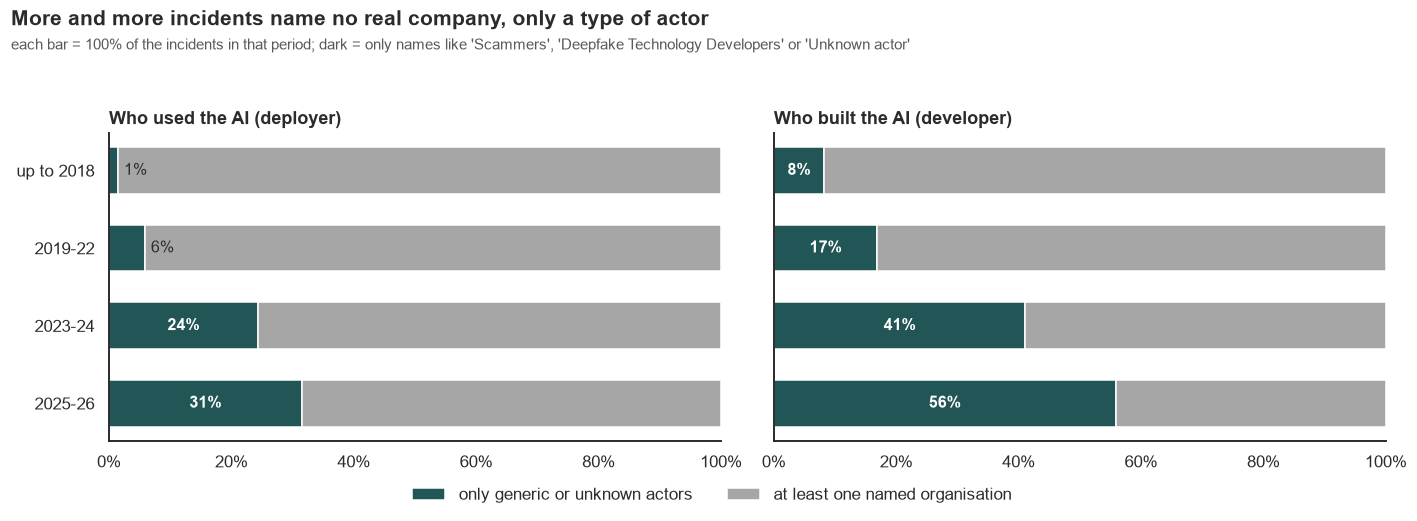

In [52]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
y = np.arange(len(anon_share))[::-1]
for a, col, name in [(ax[0], "deployer", "Who used the AI (deployer)"), (ax[1], "developer", "Who built the AI (developer)")]:
    generic = anon_share[col]
    a.barh(y, generic, color=CMP_A, height=0.6, label="only generic or unknown actors")
    a.barh(y, 100 - generic, left=generic, color=CMP_B, height=0.6, label="at least one named organisation")
    for yi, v in zip(y, generic):
        if v >= 8:
            a.text(v / 2, yi, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=10.5, fontweight="bold")
        else:
            a.text(v + 1, yi, f"{v:.0f}%", va="center", fontsize=10.5)
    a.set_xlim(0, 100)
    a.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    a.set_title(name, fontsize=12)
ax[0].set_yticks(y, anon_share.index)
fig.suptitle("More and more incidents name no real company, only a type of actor", x=0.01, ha="left",
             fontsize=13.5, fontweight="bold", y=1.04)
fig.text(0.01, 0.955, "each bar = 100% of the incidents in that period; dark = only names like 'Scammers', "
         "'Deepfake Technology Developers' or 'Unknown actor'", fontsize=9.5, color="#5A5A5A")
fig.legend(*ax[0].get_legend_handles_labels(), loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout(rect=(0, 0, 1, 0.95))
save(fig, "06a_generic_actors_by_period")
plt.show()

Up to 2018 almost every incident names a real company, both as user and as builder of the AI. In 2025-26, a third of incidents only say that "some scammers" or "someone unknown" used the AI, and more than half do not name the company that built it, only the type of tool ("deepfake technology"). The harm increasingly comes from anonymous people using widely available tools, not from one identifiable system of one company.


### 5.3 Which organisations and which actor types appear most often?

An incident counts for an organisation if it is the deployer or the developer (or both). Colours show the risk domain of the incidents.

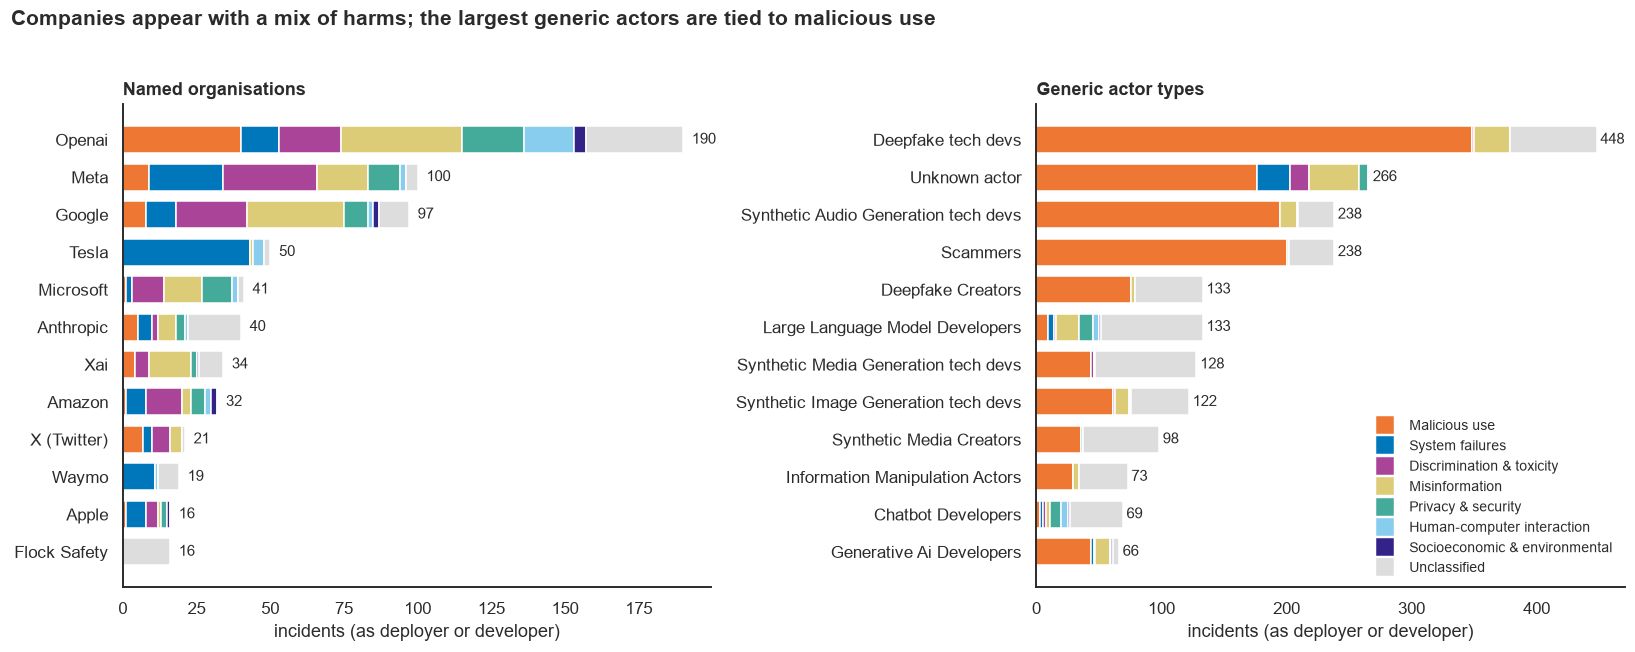

In [53]:
long = inc[["id", "dom_label"]].assign(actor=inc["deployer_list"] + inc["developer_list"]).explode("actor", ignore_index=True).dropna()
long = long.drop_duplicates(["id", "actor"])
long["kind"] = long["actor"].map(actor_kind)

def top_by_domain(kind, n=12):
    sub = long[long["kind"] == kind]
    top = sub["actor"].value_counts().head(n).index
    table = pd.crosstab(sub[sub["actor"].isin(top)]["actor"], sub["dom_label"])
    table = table.reindex(columns=DOMAINS + ["Unclassified"], fill_value=0)
    return table.loc[table.sum(axis=1).sort_values().index]

short = lambda s: textwrap.shorten(s.replace(" Technology Developers", " tech devs"), 36, placeholder="...")

fig, ax = plt.subplots(1, 2, figsize=(15, 5.8))
for a, kind, name in [(ax[0], "named", "Named organisations"), (ax[1], "generic", "Generic actor types")]:
    t = top_by_domain(kind)
    left = np.zeros(len(t))
    for d in DOMAINS + ["Unclassified"]:
        a.barh([short(i) for i in t.index], t[d], left=left, color=DOM_COLOR[d], height=0.72, edgecolor="white", linewidth=1)
        left += t[d].values
    for y, v in enumerate(t.sum(axis=1)):
        a.text(v + 3, y, f"{v}", va="center", fontsize=9.5)
    a.set_title(name, fontsize=12)
    a.set_xlabel("incidents (as deployer or developer)")
domain_legend(ax[1], loc="lower right", fontsize=9)
fig.suptitle("Companies appear with a mix of harms; the largest generic actors are tied to malicious use",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.02)
fig.tight_layout()
save(fig, "06_deployers_developers")
plt.show()

### 5.4 How deployers and developers are linked

A matrix instead of a network: drawn as nodes and links, these pairs become an unreadable hairball, while a matrix shows every pair at once. Rows are the 12 most frequent deployers, columns the 12 most frequent developers, numbers are incidents.

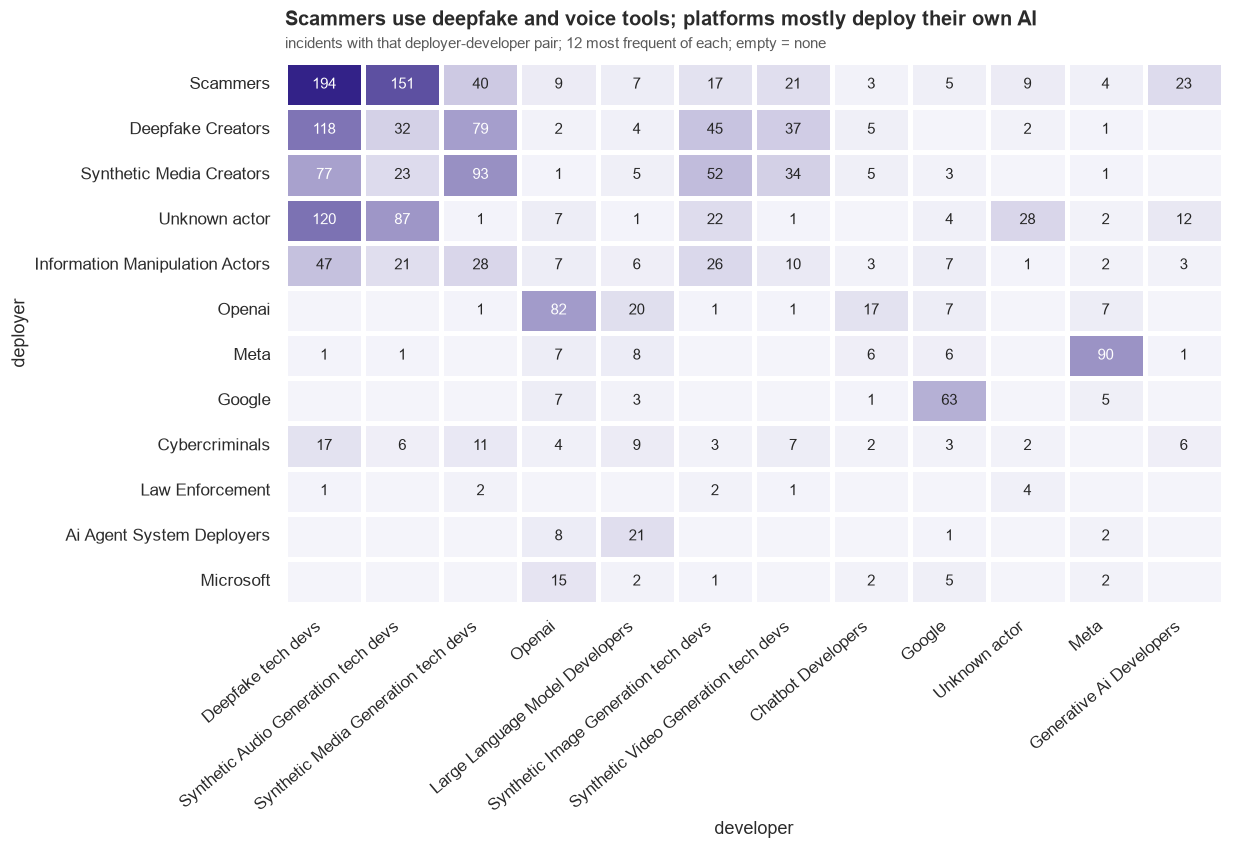

In [54]:
pairs = inc[["deployer_list", "developer_list"]].explode("deployer_list").explode("developer_list").dropna()
pairs.columns = ["deployer", "developer"]
top_dep = pairs["deployer"].value_counts().head(12).index
top_dev = pairs["developer"].value_counts().head(12).index
matrix = (pairs[pairs["deployer"].isin(top_dep) & pairs["developer"].isin(top_dev)]
          .value_counts().unstack(fill_value=0).reindex(index=top_dep, columns=top_dev, fill_value=0))

fig, ax = plt.subplots(figsize=(11, 6.4))
sns.heatmap(matrix, annot=matrix.where(matrix > 0, ""), fmt="", cmap=SEQ, cbar=False, linewidths=2, linecolor="white",
            ax=ax, annot_kws={"fontsize": 9.5})
ax.set_xticklabels([short(t.get_text()) for t in ax.get_xticklabels()], rotation=40, ha="right")
ax.set_yticklabels([short(t.get_text()) for t in ax.get_yticklabels()], rotation=0)
ax.set_xlabel("developer")
ax.set_ylabel("deployer")
titles(ax, "Scammers use deepfake and voice tools; platforms mostly deploy their own AI",
       "incidents with that deployer-developer pair; 12 most frequent of each; empty = none")
save(fig, "07_deployer_developer_links")
plt.show()

### 5.5 Who is harmed by which type of harm?

Using the harmed groups from section 2.6: for each group, how its classified incidents split across the risk domains.

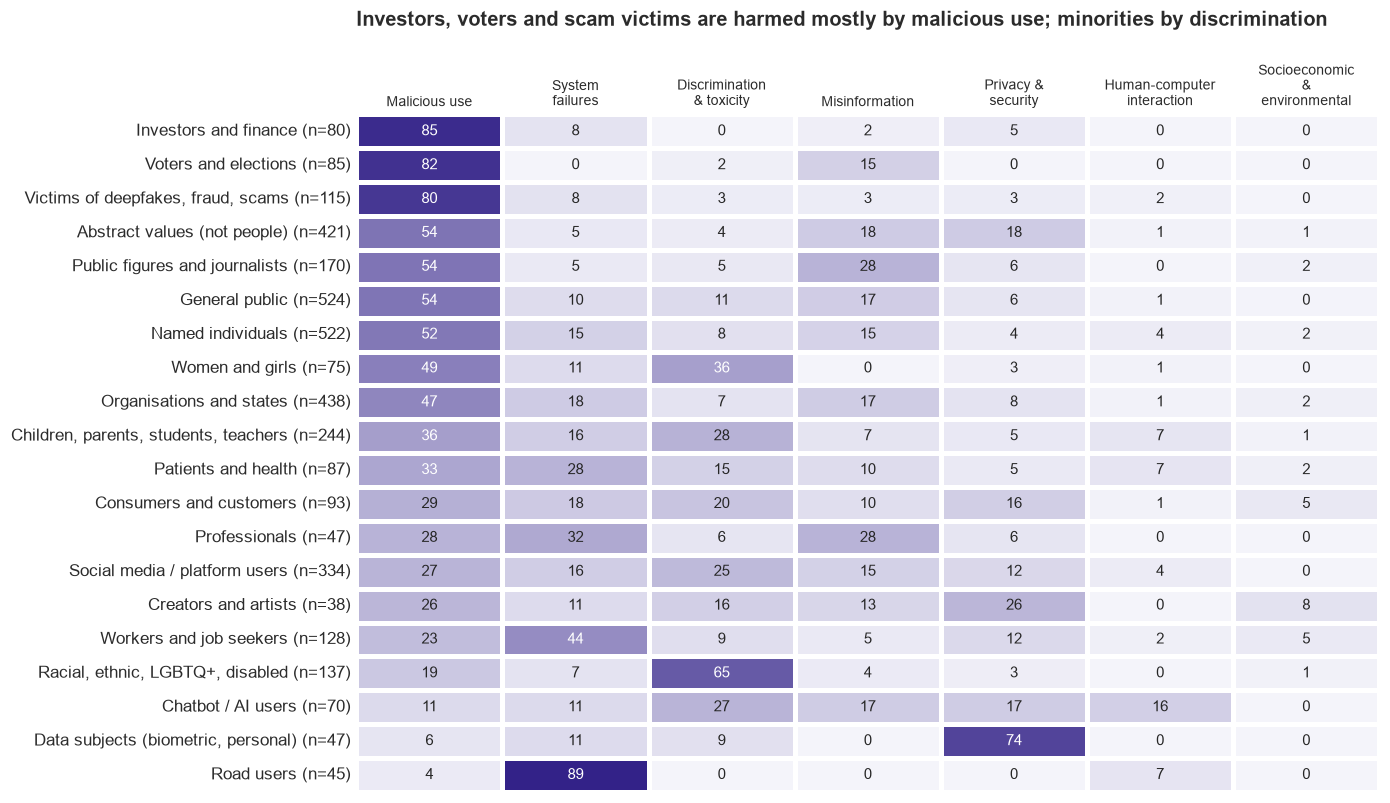

In [55]:
hg = inc.loc[inc["classified"], ["harmed_groups", "dom_label"]].explode("harmed_groups", ignore_index=True)
hg = hg[hg["harmed_groups"] != "Not grouped"]
top_groups = hg["harmed_groups"].value_counts().head(20).index
by_domain = pd.crosstab(hg["harmed_groups"], hg["dom_label"], normalize="index").reindex(index=top_groups, columns=DOMAINS) * 100
by_domain = by_domain.sort_values("Malicious use", ascending=False)
n_group = hg["harmed_groups"].value_counts()

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(by_domain, annot=True, fmt=".0f", cmap=SEQ, cbar=False, linewidths=2, linecolor="white", ax=ax,
            yticklabels=[f"{g} (n={n_group[g]})" for g in by_domain.index], annot_kws={"fontsize": 9.5})
ax.set_xticklabels([textwrap.fill(t.get_text(), 14) for t in ax.get_xticklabels()], rotation=0, fontsize=9)
ax.xaxis.tick_top()
ax.tick_params(length=0)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Investors, voters and scam victims are harmed mostly by malicious use; minorities by discrimination", pad=58)
save(fig, "08_harmed_by_domain")
plt.show()

## 6. Media attention per incident

`report_count` is the number of news articles linked to an incident. It tells us how much media attention an incident got.

### 6.1 How many reports does an incident get?

In [56]:
print(inc["report_count"].describe().round(1))
print(f"Incidents with 0 reports: {(inc['report_count'] == 0).sum()}, with more than 20: {(inc['report_count'] > 20).sum()}")

count    1748.0
mean        3.9
std         6.0
min         0.0
25%         1.0
50%         2.0
75%         4.0
max        58.0
Name: report_count, dtype: float64
Incidents with 0 reports: 1, with more than 20: 68


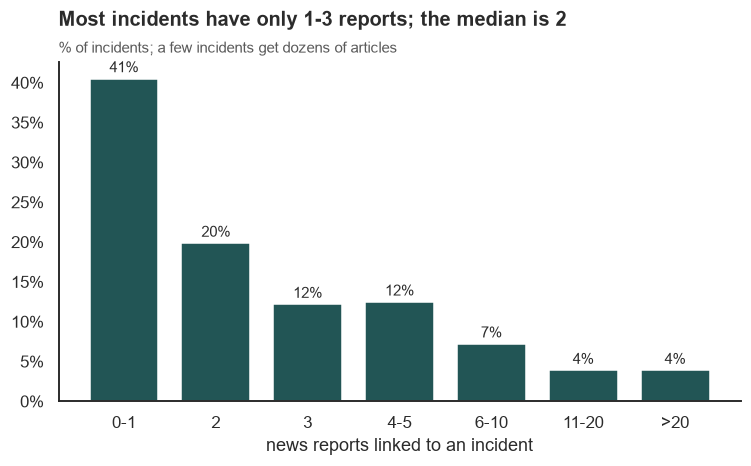

In [57]:
bins = pd.cut(inc["report_count"], [-1, 1, 2, 3, 5, 10, 20, 100],
              labels=["0-1", "2", "3", "4-5", "6-10", "11-20", ">20"])
dist = bins.value_counts(normalize=True).reindex(bins.cat.categories) * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dist.index, dist.values, color=CMP_A, width=0.75)
for x, v in enumerate(dist.values):
    ax.text(x, v + 0.8, f"{v:.0f}%", ha="center", fontsize=10)
ax.set_xlabel("news reports linked to an incident")
ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
titles(ax, f"Most incidents have only 1-3 reports; the median is {inc['report_count'].median():.0f}",
       "% of incidents; a few incidents get dozens of articles")
save(fig, "09a_report_count_distribution")
plt.show()

The distribution is very skewed: half of the incidents have two reports or fewer, a few have more than 20. So for comparisons we use the **median** and a rank-based test, not the mean.

### 6.2 Does coverage depend on the type of harm?


We compare the number of reports across the seven risk domains with the **Kruskal-Wallis test** (the rank-based version of a one-way ANOVA, fine for skewed counts). The p-value says whether the domains differ at all; the effect size **epsilon-squared** says how much (0 = no difference, 1 = the domain explains everything; around 0.01 is small, 0.08 medium, 0.26 large).

In [58]:
from scipy import stats

cls = inc[inc["classified"]]
groups = [g["report_count"].values for _, g in cls.groupby("domain", observed=True)]
kw = stats.kruskal(*groups)
eps2 = (kw.statistic - len(groups) + 1) / (len(cls) - len(groups))

print(f"Kruskal-Wallis: H = {kw.statistic:.1f}, p = {kw.pvalue:.4f}, epsilon-squared = {eps2:.3f}")
cls.groupby("domain", observed=True)["report_count"].agg(["count", "median", "mean"]).round(1)

Kruskal-Wallis: H = 38.5, p = 0.0000, epsilon-squared = 0.022


,count,median,mean
domain,,,
Malicious use,566,2.0,3.6
System failures,312,2.0,4.8
Discrimination & toxicity,243,2.0,4.4
Misinformation,196,2.0,3.7
Privacy & security,112,2.0,4.1
Human-computer interaction,42,2.0,5.2
Socioeconomic & environmental,24,3.0,5.9


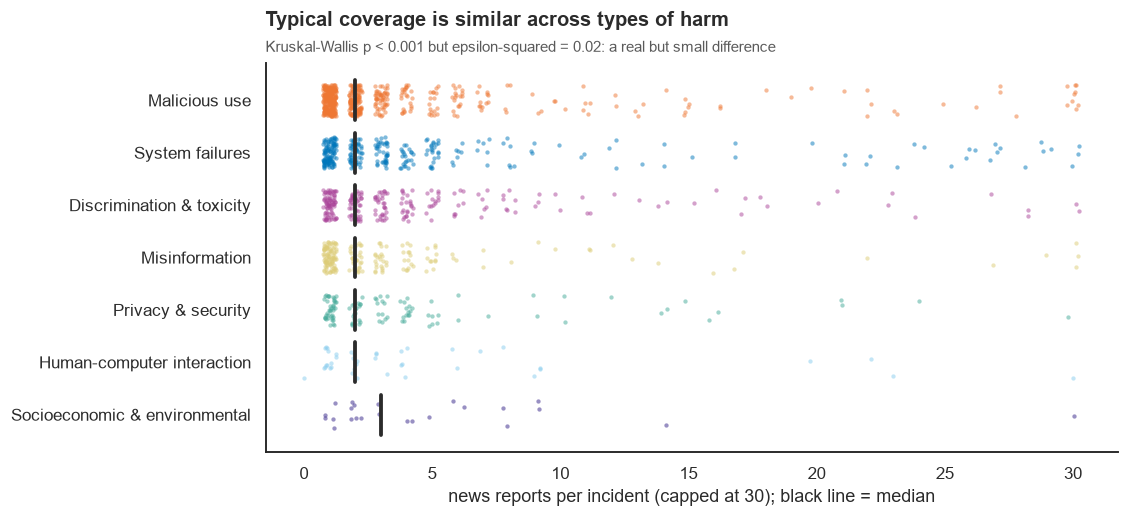

In [59]:
rng = np.random.default_rng(SEED)
medians = cls.groupby("domain", observed=True)["report_count"].median()

fig, ax = plt.subplots(figsize=(10, 4.6))
for k, d in enumerate(DOMAINS):
    v = cls.loc[cls["domain"] == d, "report_count"].clip(upper=30)
    ax.scatter(v + rng.uniform(-0.25, 0.25, len(v)), k + rng.uniform(-0.3, 0.3, len(v)),
               s=8, color=DOM_COLOR[d], alpha=0.5, linewidths=0)
    ax.plot([medians[d]] * 2, [k - 0.38, k + 0.38], color=INK, lw=2.5)
ax.set_yticks(range(len(DOMAINS)), DOMAINS)
ax.invert_yaxis()
ax.set_xlabel("news reports per incident (capped at 30); black line = median")
titles(ax, "Typical coverage is similar across types of harm",
       f"Kruskal-Wallis p < 0.001 but epsilon-squared = {eps2:.2f}: a real but small difference")
save(fig, "09_report_counts")
plt.show()

The test is significant (p < 0.001), but the effect is small (epsilon-squared = 0.02): with 1,500 incidents even tiny differences become "significant", so the effect size is the more useful number. The median is 2 reports in almost every domain. If anything, malicious use gets slightly *fewer* reports per incident than system failures (mean 3.6 vs 4.8), so its rise in the database is not because each misuse incident gets more media attention.

### 6.3 The incidents that made the biggest headlines

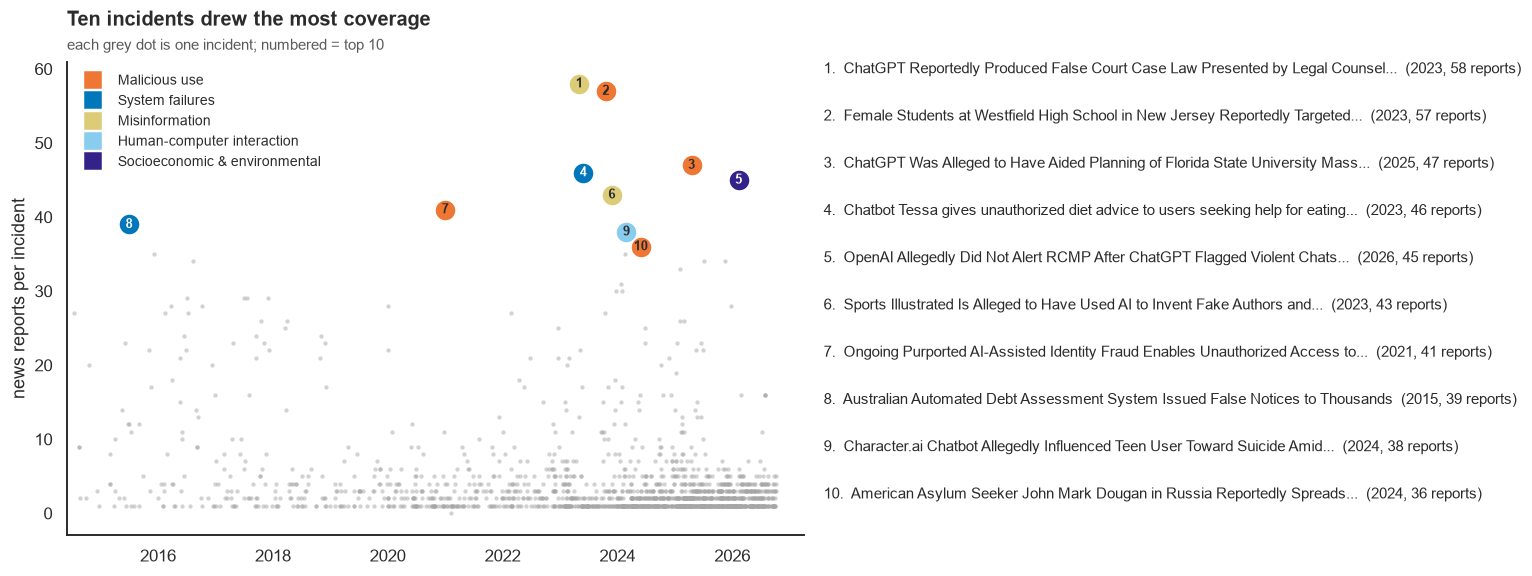

In [60]:
top = inc.nlargest(10, "report_count").reset_index(drop=True)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.15, 1]})
ax.scatter(inc["date"], inc["report_count"], s=8, color=CMP_B, alpha=0.5, linewidths=0)
for i, r in top.iterrows():
    ax.scatter(r["date"], r["report_count"], s=190, color=DOM_COLOR[r["dom_label"]], zorder=3, edgecolor="white")
    ax.text(r["date"], r["report_count"], str(i + 1), ha="center", va="center", fontsize=8.5, zorder=4,
            color=INK if r["dom_label"] in DARK_TEXT else "white", fontweight="bold")
ax.set_xlim(pd.Timestamp("2014-06-01"), pd.Timestamp("2027-04-01"))
ax.set_ylabel("news reports per incident")
domain_legend(ax, names=[d for d in DOMAINS if d in set(top["dom_label"])], loc="upper left", fontsize=9)
titles(ax, "Ten incidents drew the most coverage", "each grey dot is one incident; numbered = top 10")

ax2.axis("off")
for i, r in top.iterrows():
    ax2.text(0, 1 - i * 0.1, f"{i + 1}.  {textwrap.shorten(r['title'], 80, placeholder='...')}  "
             f"({r['date'].year}, {r['report_count']} reports)", fontsize=9.5, va="top", transform=ax2.transAxes)
fig.tight_layout()
save(fig, "10_top_incidents_timeline")
plt.show()

## 7. Topic modelling of the incidents

### 7.1 Preparing the text

In [61]:
from sklearn.decomposition import NMF, LatentDirichletAllocation, TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import normalized_mutual_info_score

STOP = list(CountVectorizer(stop_words="english").get_stop_words()) + [
    "ai", "reportedly", "allegedly", "purportedly", "used", "using", "use", "said", "according", "incident", "system", "systems", "people", "based", "generated", "created", "included", "following", "one", "two", "new", "also", "including", "reported", "involving", "after", "claims", "old", "year", "years"]

docs = inc["text"].tolist()
tfidf = TfidfVectorizer(stop_words=STOP, min_df=5, max_df=0.5, sublinear_tf=True)
X_tfidf = tfidf.fit_transform(docs)
vocab = tfidf.get_feature_names_out()
X_cnt = CountVectorizer(vocabulary=tfidf.vocabulary_).fit_transform(docs)
print(f"{X_tfidf.shape[0]:,} incidents, {X_tfidf.shape[1]:,} words (in at least 5 texts, at most 50%)")

1,748 incidents, 2,433 words (in at least 5 texts, at most 50%)


Domain-specific filler words ("reportedly", "allegedly", "AI") are added to the standard English stop words, because they appear in almost every description and would end up in every topic. Both matrices use exactly the same vocabulary, so the coherence of NMF and LDA topics is measured on the same words.

Helper functions to judge the topic models. There is no single correct measure, so we use standard ones from the literature and also read the top words of every topic ourselves:

* `top_words` – the strongest words of each topic.
* `coherence` – do a topic's top words appear together in the same incidents? (UMass coherence, Mimno et al., 2011). Closer to 0 is better.
* `diversity` – share of different words among all top words; 1 = topics share no words (Dieng et al., 2020).
* `nmi_domain` – how well the topics match the official risk domains (normalized mutual information; 0 = not at all, 1 = exactly).

Coherence and diversity are the measures most often used to compare LDA, NMF and BERTopic (e.g. Mahmoud et al., 2025; Mihajlov et al., 2024). We also add **stability** (Greene et al., 2014; Belford et al., 2018): a reliable model gives nearly the same topics when run again with a different random start.

In [62]:
def top_words(components, n=10):
    return np.argsort(-components, axis=1)[:, :n]

def coherence(top_idx, X_counts):
    B = (X_counts > 0).astype(int)
    co = (B.T @ B).toarray()
    scores = [np.log((co[w[m], w[l]] + 1) / co[w[l], w[l]])
              for w in top_idx for m in range(1, len(w)) for l in range(m)]
    return np.mean(scores)

def diversity(top_idx):
    return len(set(top_idx.ravel())) / top_idx.size

classified = inc["classified"].values
def nmi_domain(labels):
    return normalized_mutual_info_score(inc.loc[classified, "domain"].astype(str), np.asarray(labels)[classified])

### 7.2 How many topics? - NMF vs LDA

In [63]:
rows = []
for k in [6, 8, 10, 12, 15, 20]:
    for name in ["NMF", "LDA"]:
        if name == "NMF":
            fits = [NMF(k, init="random", random_state=s, max_iter=400).fit(X_tfidf) for s in range(4)]
            labels = [f.transform(X_tfidf).argmax(axis=1) for f in fits]
        else:
            fits = [LatentDirichletAllocation(k, learning_method="batch", max_iter=20, random_state=s).fit(X_cnt) for s in range(4)]
            labels = [f.transform(X_cnt).argmax(axis=1) for f in fits]
        tw = top_words(fits[0].components_)
        rows.append({"k": k, "method": name,
                     "coherence": coherence(tw, X_cnt),
                     "diversity": diversity(tw),
                     "stability": np.mean([normalized_mutual_info_score(labels[i], labels[j]) for i in range(4) for j in range(i + 1, 4)]),
                     "NMI with domain": nmi_domain(labels[0])})
sweep = pd.DataFrame(rows)
sweep.pivot(index="k", columns="method").round(2)

coherence       diversity       stability       NMI with domain      
method       LDA   NMF       LDA   NMF       LDA   NMF             LDA   NMF
k                                                                           
6          -2.58 -1.81      0.97  0.95      0.31  0.74            0.22  0.27
8          -2.47 -1.72      0.92  0.96      0.30  0.78            0.21  0.27
10         -2.39 -1.85      0.89  0.95      0.29  0.79            0.22  0.27
12         -2.50 -1.81      0.80  0.94      0.28  0.78            0.19  0.26
15         -2.43 -1.87      0.81  0.93      0.27  0.78            0.21  0.26
20         -2.28 -1.98      0.80  0.92      0.28  0.82            0.18  0.24

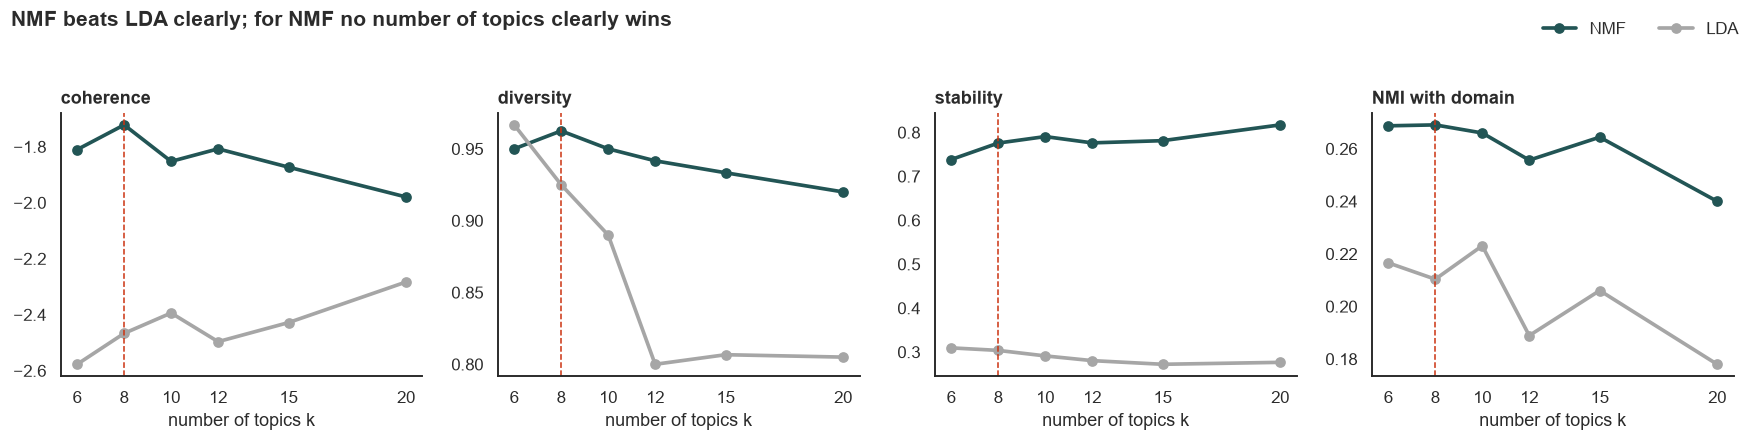

In [64]:
measures = ["coherence", "diversity", "stability", "NMI with domain"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, m in zip(axes, measures):
    for name, color in [("NMF", CMP_A), ("LDA", CMP_B)]:
        s = sweep[sweep["method"] == name]
        ax.plot(s["k"], s[m], marker="o", lw=2.4, color=color, label=name)
    ax.axvline(8, color=HIGHLIGHT, lw=1, ls="--")
    ax.set_title(m, fontsize=11.5)
    ax.set_xlabel("number of topics k")
    ax.set_xticks(sweep["k"].unique())
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2, bbox_to_anchor=(1, 1.06))
fig.suptitle("NMF beats LDA clearly; for NMF no number of topics clearly wins", x=0.01, ha="left",
             fontsize=13.5, fontweight="bold", y=1.05)
fig.tight_layout()
save(fig, "13_topic_number_sweep")
plt.show()

NMF is better than LDA at almost every k: more coherent, more distinct, closer to the domains and far more stable (LDA gives different topics with a different random start, stability about 0.3). For NMF the differences between k values are small. k = 8 has the best coherence and diversity; k = 10 only adds an election topic and splits self-driving cars into Tesla and Waymo. We choose **k = 8**.

### 7.3 The NMF topics

In [65]:
K_TOPICS = 8
nmf = NMF(K_TOPICS, init="nndsvd", random_state=SEED, max_iter=500).fit(X_tfidf)
inc["topic_nmf"] = nmf.transform(X_tfidf).argmax(axis=1)
tw_nmf = top_words(nmf.components_, 8)
topic_name = {k: ", ".join(vocab[tw_nmf[k][:3]]) for k in range(K_TOPICS)}

per_topic = pd.crosstab(inc["topic_nmf"], inc["dom_label"]).reindex(columns=DOMAINS + ["Unclassified"], fill_value=0)
dom_share = per_topic[DOMAINS].div(per_topic[DOMAINS].sum(axis=1), axis=0) * 100
summary = pd.DataFrame({"top words": [", ".join(vocab[tw_nmf[k]]) for k in range(K_TOPICS)],
                        "incidents": per_topic.sum(axis=1),
                        "main domain": dom_share.idxmax(axis=1),
                        "% of classified in main domain": dom_share.max(axis=1).round(0)}).sort_values("incidents", ascending=False)
summary

,top words,incidents,main domain,% of classified in main domain
topic_nmf,,,,
1,"data, google, chatgpt, openai, user, chatbot, ...",370,Privacy & security,21.0
5,"video, purported, deepfake, president, circula...",275,Malicious use,72.0
7,"content, facebook, moderation, automated, algo...",245,Discrimination & toxicity,42.0
4,"images, school, students, student, explicit, c...",211,Malicious use,59.0
0,"scam, deepfake, investment, scammers, voice, f...",205,Malicious use,97.0
6,"court, citations, legal, case, chatgpt, attorn...",156,Misinformation,48.0
3,"facial, recognition, police, black, arrest, te...",144,Discrimination & toxicity,35.0
2,"tesla, autopilot, driver, crashed, model, driv...",142,System failures,91.0


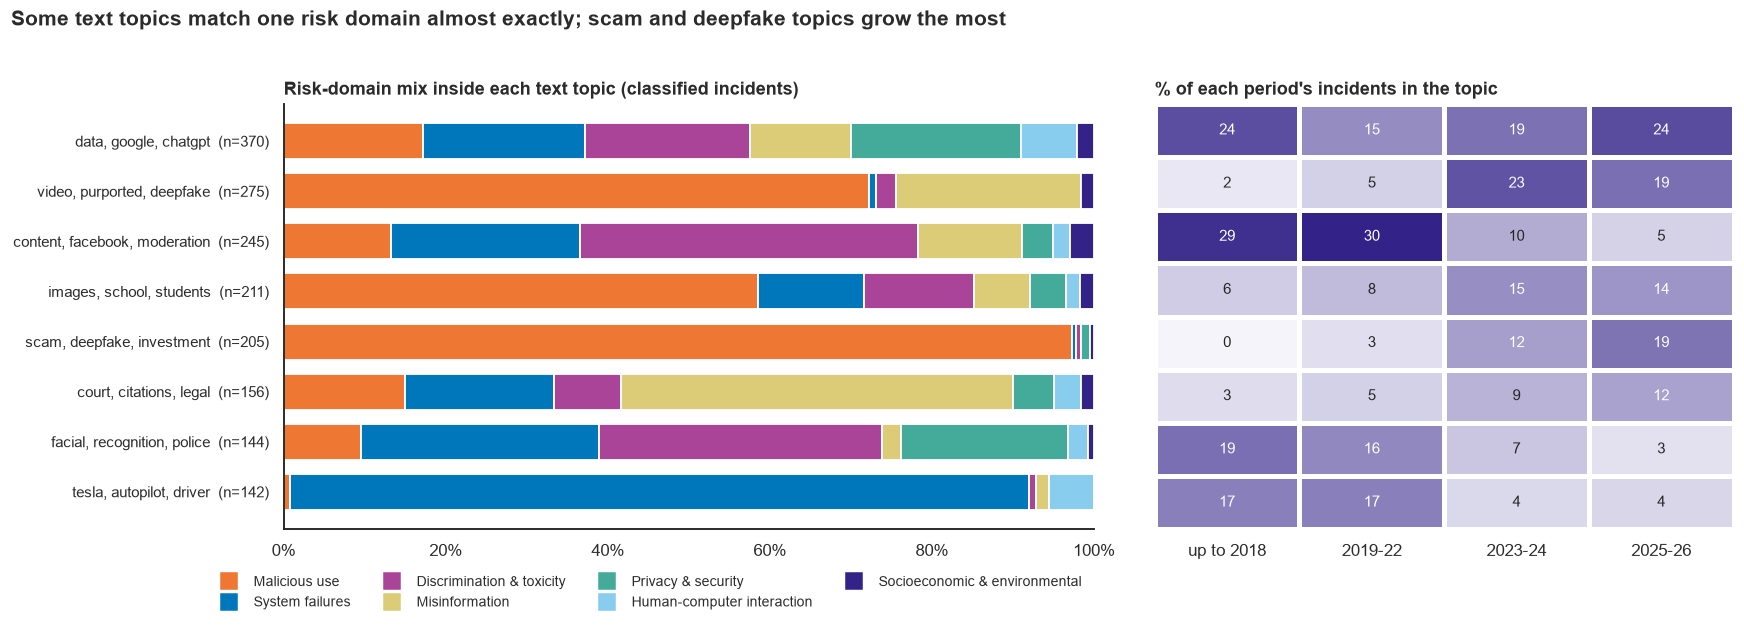

In [66]:
order = summary.index.tolist()
by_period = pd.crosstab(inc["topic_nmf"], inc["period"], normalize="columns").loc[order] * 100

fig, ax = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1.4, 1]})

y = np.arange(len(order))[::-1]
left = np.zeros(len(order))
for d in DOMAINS:
    ax[0].barh(y, dom_share.loc[order, d], left=left, color=DOM_COLOR[d], height=0.72, edgecolor="white", linewidth=1.2)
    left += dom_share.loc[order, d].values
ax[0].set_yticks(y, [f"{topic_name[k]}  (n={per_topic.sum(axis=1)[k]})" for k in order], fontsize=9.5)
ax[0].set_xlim(0, 100)
ax[0].xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax[0].set_title("Risk-domain mix inside each text topic (classified incidents)", fontsize=11.5)
domain_legend(ax[0], names=DOMAINS, loc="upper center", bbox_to_anchor=(0.45, -0.08), ncol=4, fontsize=9)

sns.heatmap(by_period, annot=True, fmt=".0f", cmap=SEQ, cbar=False, ax=ax[1], linewidths=2, linecolor="white",
            yticklabels=False, annot_kws={"fontsize": 9.5})
ax[1].set_xlabel("")
ax[1].set_ylabel("")
ax[1].set_title("% of each period's incidents in the topic", fontsize=11.5)

fig.suptitle("Some text topics match one risk domain almost exactly; scam and deepfake topics grow the most",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.02)
fig.tight_layout()
save(fig, "14_nmf_topics")
plt.show()

Each topic is labelled by its three strongest words. Some topics match one risk domain almost exactly: *scam, deepfake, investment* is 97% malicious use and *tesla, autopilot, driver* 91% system failures. Others are mixed, above all the largest topic *data, google, chatgpt*, which collects incidents about chatbots and data from every domain. Over time the scam, deepfake and school-image topics grow, while content moderation, facial recognition and Tesla shrink.

### 7.4 Embedding and clustering (BERTopic style)

NMF beat LDA, but both methods only count words. Before we settle on NMF, we check it against a method of a different kind: BERTopic-style clustering, which groups texts by meaning.

Each text is turned into a vector, and UMAP reduces the vectors to 5 dimensions for clustering (the BERTopic default; with all 384 dimensions the distances become too similar to find groups) and, separately, to 2 dimensions for drawing the map. HDBSCAN finds the number of clusters itself and leaves unclear texts unassigned ("noise"). Clusters are named with class-based TF-IDF, as in BERTopic.

As embedding we use the pretrained sentence model **all-MiniLM-L6-v2** (`sentence-transformers`), the default in BERTopic. It turns each description into a vector that captures meaning, so texts about the same thing end up close together even if they use different words. The vectors are saved to a file so the result can be reproduced without running the model again.

In [67]:
import umap
from sklearn.cluster import HDBSCAN

import os
from sentence_transformers import SentenceTransformer

if os.path.exists("data/embeddings.npy"):
    E = np.load("data/embeddings.npy")
else:
    model = SentenceTransformer("all-MiniLM-L6-v2")
    E = model.encode(docs, normalize_embeddings=True, show_progress_bar=True)
    np.save("data/embeddings.npy", E)

z5 = umap.UMAP(n_neighbors=15, min_dist=0.0, n_components=5, metric="cosine", random_state=SEED, n_jobs=1).fit_transform(E)
xy = umap.UMAP(n_neighbors=15, min_dist=0.05, n_components=2, metric="cosine", random_state=SEED, n_jobs=1).fit_transform(E)
inc["cl"] = HDBSCAN(min_cluster_size=15, min_samples=5, copy=True).fit_predict(z5)
inc["x"], inc["y"] = xy[:, 0], xy[:, 1]

n_cl = inc.loc[inc["cl"] >= 0, "cl"].nunique()
print(f"{n_cl} clusters; {(inc['cl'] == -1).mean():.0%} of incidents left unassigned (noise)")

c:\Users\natal\Dual Degree jupyter\ai-incidents-analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


29 clusters; 17% of incidents left unassigned (noise)


In [68]:
def cluster_top_words(labels, n=10):
    ids = sorted(set(labels) - {-1})
    counts = np.vstack([np.asarray(X_cnt[labels == i].sum(axis=0)).ravel() for i in ids])
    tf = counts / counts.sum(axis=1, keepdims=True)
    idf = np.log(1 + counts.sum(axis=1).mean() / (counts.sum(axis=0) + 1))
    return ids, np.argsort(-(tf * idf), axis=1)[:, :n]

cl_ids, tw_cl = cluster_top_words(inc["cl"].values)
cl_name = {i: ", ".join(vocab[tw_cl[j][:2]]) for j, i in enumerate(cl_ids)}
pd.DataFrame({"incidents": inc["cl"].value_counts().reindex(cl_ids),
              "top words": [", ".join(vocab[t[:6]]) for t in tw_cl]}, index=cl_ids).sort_values("incidents", ascending=False).head(12)

,incidents,top words
26,255,"deepfake, video, purported, scam, investment, ..."
25,120,"images, school, students, explicit, deepfake, ..."
24,113,"image, kosovo, images, video, media, facebook"
27,104,"agent, claude, anthropic, phishing, malware, data"
15,75,"facial, recognition, police, arrest, face, tec..."
18,63,"chatbot, meta, chatbots, character, user, users"
21,59,"chatgpt, chatbot, openai, attack, suicide, pla..."
17,52,"citations, court, legal, case, brief, filing"
4,50,"tesla, autopilot, driver, model, crashed, mode"
9,49,"facebook, content, moderation, automated, post..."


In [69]:
rows = []
for mcs in [10, 15, 20, 30]:
    labels = HDBSCAN(min_cluster_size=mcs, min_samples=5, copy=True).fit_predict(z5)
    rows.append({"min_cluster_size": mcs,
                 "clusters": len(set(labels) - {-1}),
                 "noise %": round((labels == -1).mean() * 100),
                 "NMI with domain": round(nmi_domain(labels), 2)})
pd.DataFrame(rows).set_index("min_cluster_size")

,clusters,noise %,NMI with domain
min_cluster_size,,,
10,56,27,0.25
15,29,17,0.26
20,25,18,0.26
30,2,0,0.14


The minimum cluster size changes the number of clusters a lot (56 with 10, 29 with 15, 25 with 20), but the agreement with the domains stays the same (NMI 0.25-0.26). With 30, HDBSCAN merges almost everything into 2 clusters, which is useless. We keep 15, a middle setting.

**How to read the map.** Each point is an incident; points close together have similar descriptions (position has no units). The colour shows the official risk domain of the incident. The labels show the clusters found by HDBSCAN: each of the clusters with 30+ incidents is named by its two most typical words (frequent in that cluster, rare in the others). Smaller clusters are not labelled, so the map stays readable.

In [70]:
# set up for plotting the UMAP map of incidents
import matplotlib.patheffects as pe

xlim = np.percentile(inc["x"], [2, 98]) + np.array([-1, 1])
ylim = np.percentile(inc["y"], [2, 98]) + np.array([-1, 1])
cl_size = inc.loc[inc["cl"] >= 0, "cl"].value_counts()
big = cl_size[cl_size >= 30].index
SUB = "each point is an incident; nearby points have similar descriptions; position has no units, only closeness matters"

def map_colour(d):
    if d in ["Malicious use", "System failures"]:
        return DOM_COLOR[d]
    return "#8A8A8A"

inc["map_colour"] = inc["dom_label"].map(map_colour)

def finish_map(ax, fig, name, title, bold_labels=True):
    for c in big:
        pts = inc[inc["cl"] == c]
        ax.text(pts["x"].median(), pts["y"].median(), textwrap.fill(cl_name[c], 14), ha="center", va="center",
                fontsize=9, fontweight="bold" if bold_labels else "normal", color="#333333",
                path_effects=[pe.withStroke(linewidth=3, foreground="white")], zorder=5)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.axis("off")
    titles(ax, title, SUB)
    fig.subplots_adjust(left=0.02, right=0.98, top=0.86, bottom=0.12)
    fig.savefig(FIG_DIR / f"{name}.png", facecolor="white")   # no tight crop: all maps get the same size
    plt.show()

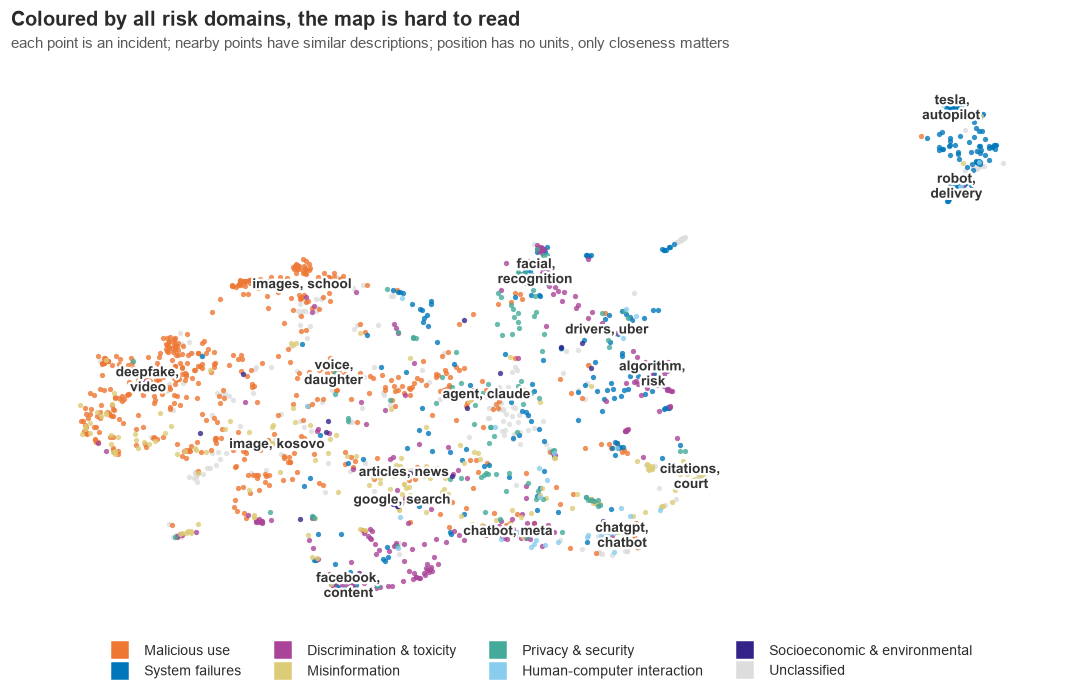

In [71]:
fig, ax = plt.subplots(figsize=(10, 7))
for d in ["Unclassified"] + DOMAINS:
    s = inc[inc["dom_label"] == d]
    ax.scatter(s["x"], s["y"], s=12, color=DOM_COLOR[d], alpha=0.8, linewidths=0)
domain_legend(ax, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4, fontsize=9)
finish_map(ax, fig, "15_map_1_all_domains", "Coloured by all risk domains, the map is hard to read")

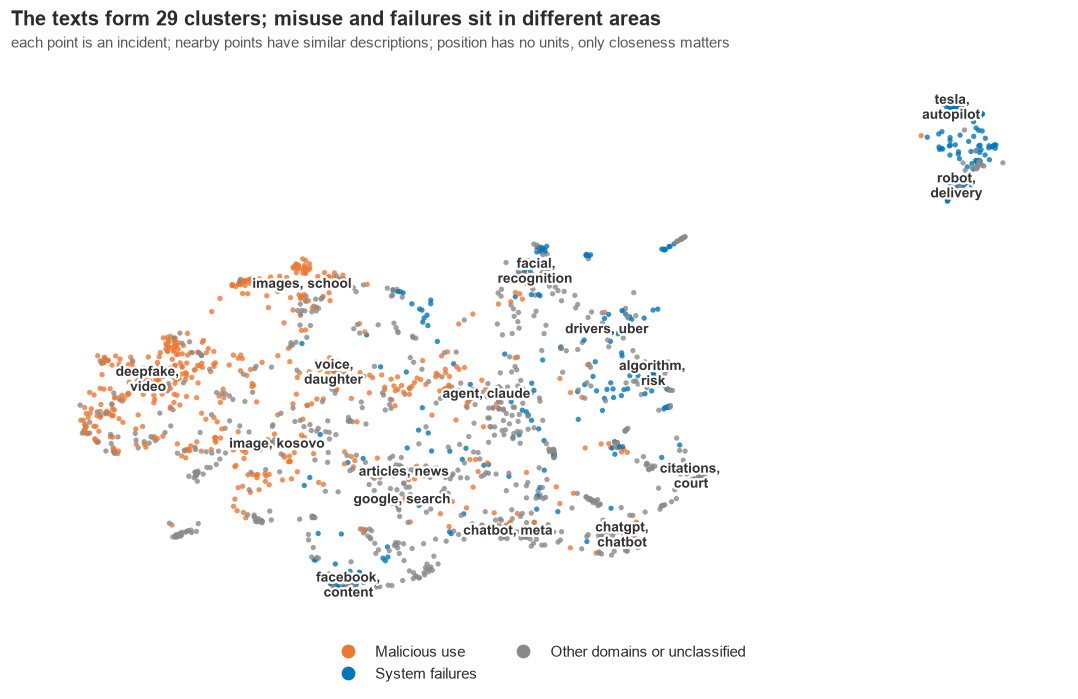

In [72]:
handles = [plt.Line2D([], [], marker="o", ls="", color=c, markersize=8, label=l) for c, l in
           [(DOM_COLOR["Malicious use"], "Malicious use"), (DOM_COLOR["System failures"], "System failures"),
            ("#8A8A8A", "Other domains or unclassified"), ("#E6E6E6", "incidents of the other periods")]]

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(inc["x"], inc["y"], s=12, color=inc["map_colour"], alpha=0.8, linewidths=0)
ax.legend(handles=handles[:3], loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, fontsize=10)
finish_map(ax, fig, "15_map_2_overview", f"The texts form {len(cl_size)} clusters; misuse and failures sit in different areas")

With only three colours the pattern is clear: malicious use (red) fills the left side of the map with several separate groups (deepfake videos, explicit images of students, scams, voice cloning), while system failures (blue) sit on the right and in a separate island of self-driving cars.

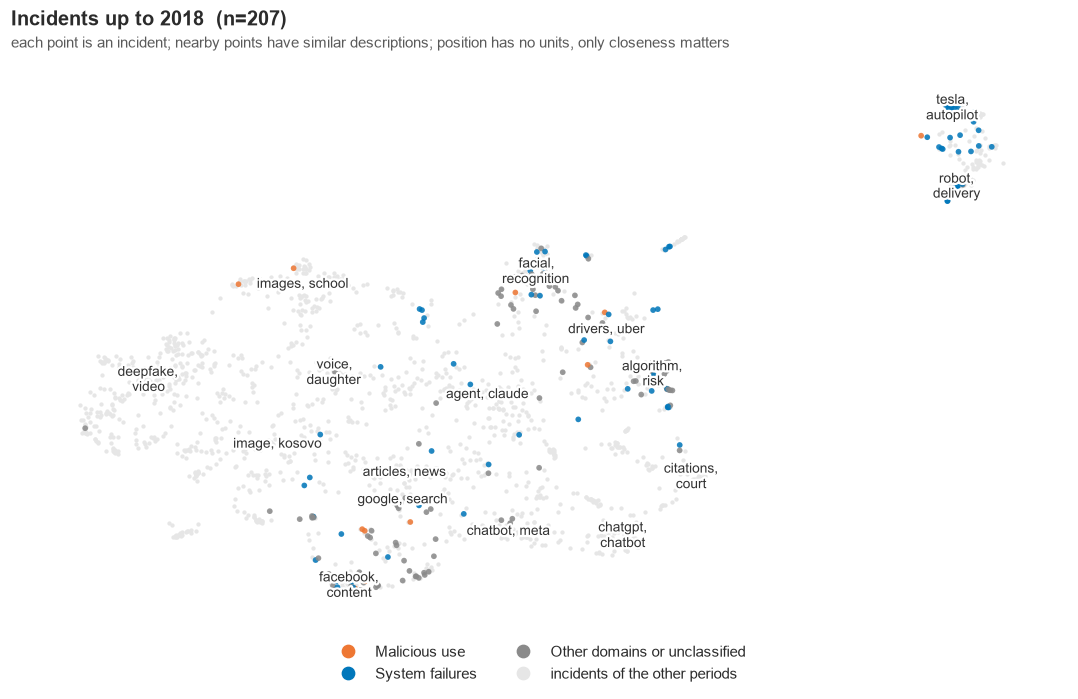

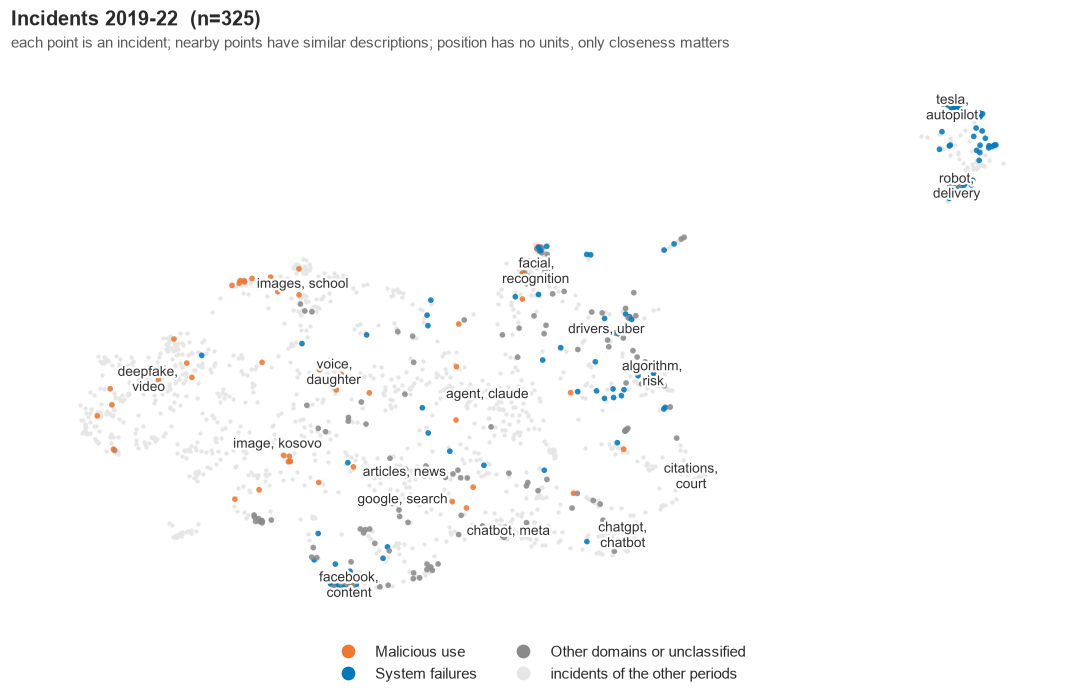

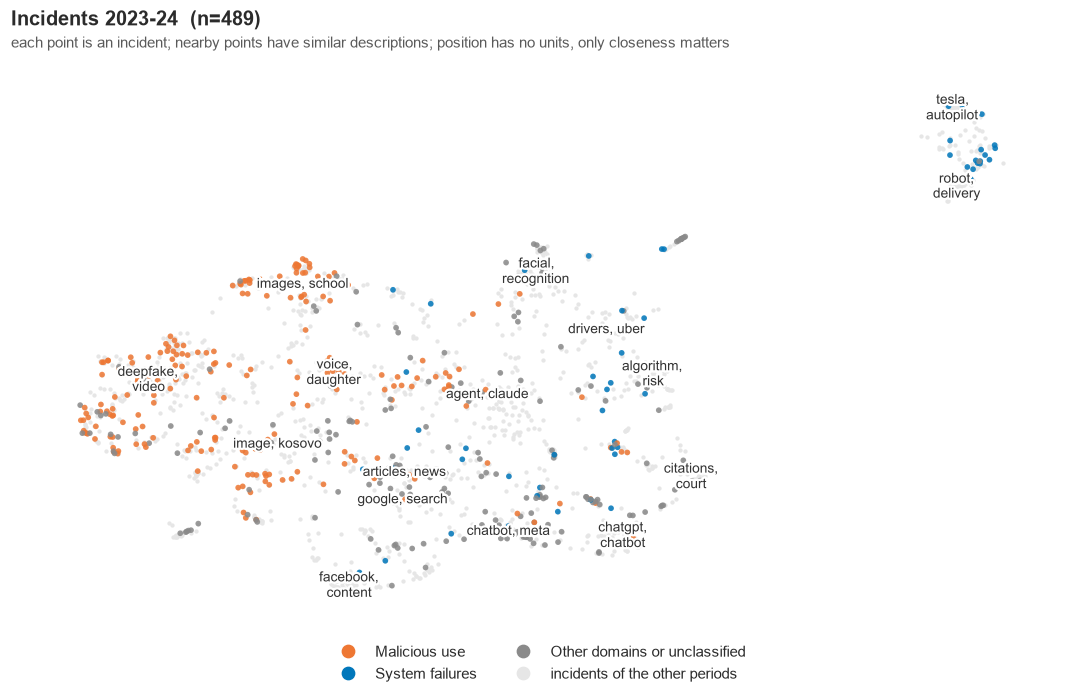

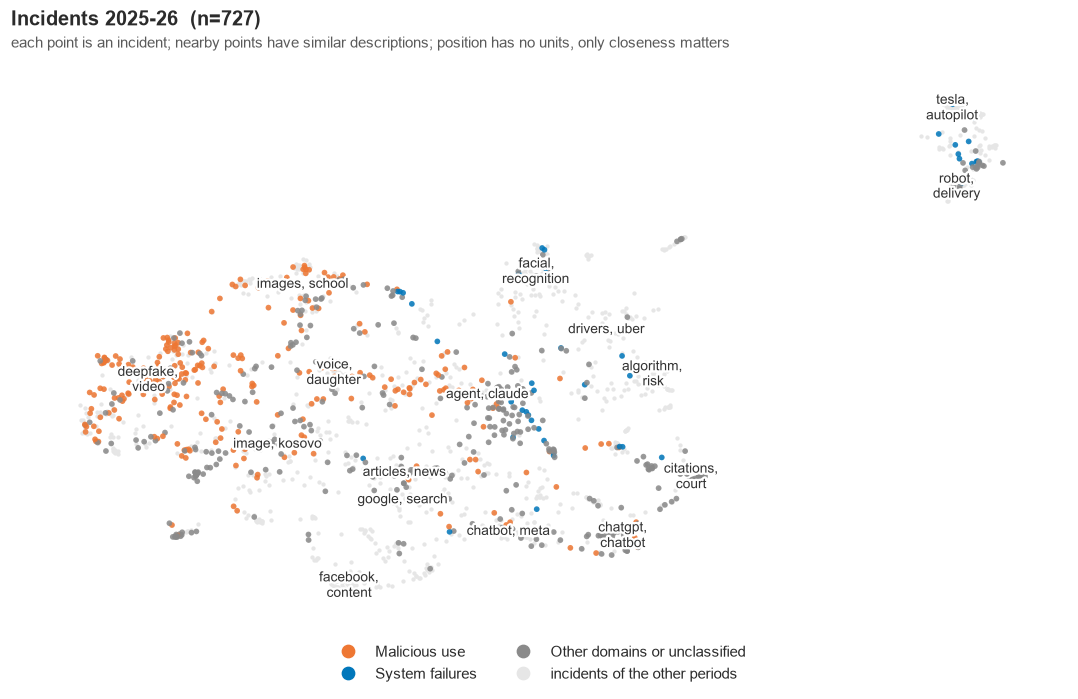

In [73]:
for i, p in enumerate(PERIODS, start=3):
    s = inc[inc["period"] == p]
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.scatter(inc["x"], inc["y"], s=8, color="#E6E6E6", linewidths=0)       # all incidents as background
    ax.scatter(s["x"], s["y"], s=14, color=s["map_colour"], alpha=0.85, linewidths=0)
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, fontsize=10)
    finish_map(ax, fig, f"15_map_{i}_{p.replace(' ', '_')}", f"Incidents {p}  (n={len(s)})", bold_labels=False)

Over time the new incidents move across the map. Up to 2022 most coloured points are blue and sit on the right (self-driving cars, facial recognition, algorithms); from 2023 red points fill the left side.

### 7.5 Comparing the three methods

First a visual comparison. NMF and LDA give each incident a topic but no position, so they cannot draw their own map. We paint the NMF topics onto the map from 7.4: if a topic sits in one area, the word-based NMF and the meaning-based embedding agree on that theme; a topic spread across the map is a mix.

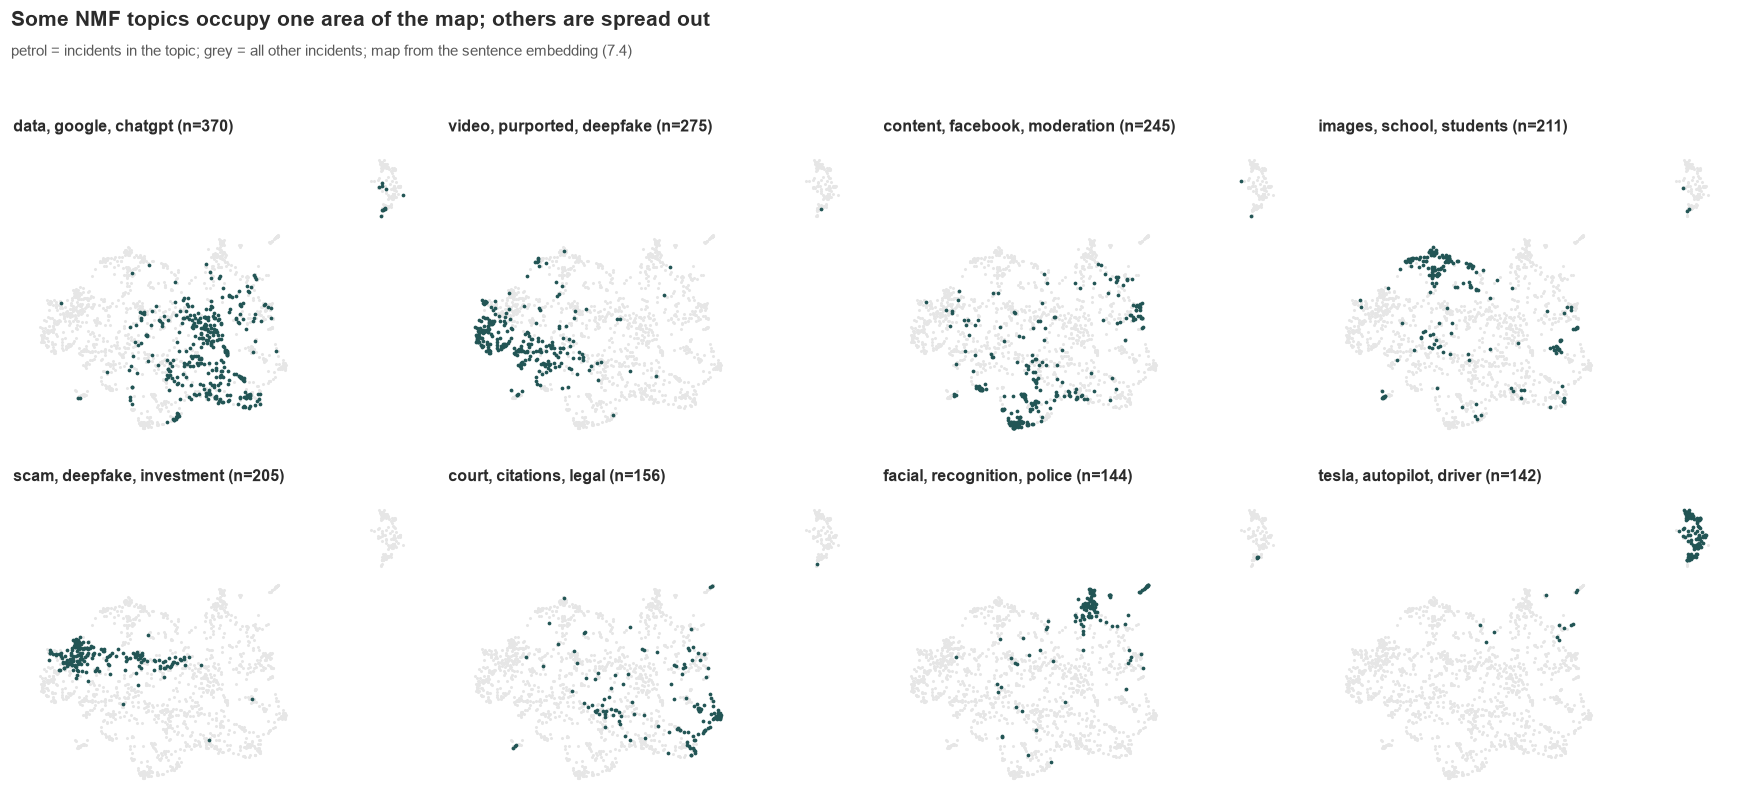

In [74]:
order = inc["topic_nmf"].value_counts().index

fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for ax, k in zip(axes.ravel(), order):
    s = inc[inc["topic_nmf"] == k]
    ax.scatter(inc["x"], inc["y"], s=4, color="#E6E6E6", linewidths=0)
    ax.scatter(s["x"], s["y"], s=6, color=CMP_A, linewidths=0)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.axis("off")
    ax.set_title(f"{topic_name[k]} (n={len(s)})", fontsize=10.5)
fig.suptitle("Some NMF topics occupy one area of the map; others are spread out",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.text(0.01, 0.925, "petrol = incidents in the topic; grey = all other incidents; map from the sentence embedding (7.4)",
         fontsize=10, color="#5A5A5A")
fig.tight_layout(rect=(0, 0, 1, 0.92))
save(fig, "16_nmf_topics_on_map")
plt.show()

Then the numbers: all three methods are compared on the same measures as in 7.2.

In [75]:
lda = LatentDirichletAllocation(K_TOPICS, learning_method="batch", max_iter=20, random_state=SEED).fit(X_cnt)
inc["topic_lda"] = lda.transform(X_cnt).argmax(axis=1)
tw_lda = top_words(lda.components_)
tw_nmf10 = top_words(nmf.components_)

assigned = inc["cl"].values >= 0

comparison = pd.DataFrame({
    "topics / clusters": [K_TOPICS, K_TOPICS, n_cl],
    "incidents assigned (%)": [100, 100, round(assigned.mean() * 100)],
    "coherence": [coherence(tw_nmf10, X_cnt), coherence(tw_lda, X_cnt), coherence(tw_cl, X_cnt)],
    "diversity": [diversity(tw_nmf10), diversity(tw_lda), diversity(tw_cl)],
    "NMI with domain": [nmi_domain(inc["topic_nmf"]), nmi_domain(inc["topic_lda"]), nmi_domain(inc["cl"])]},
    index=["NMF", "LDA", "MiniLM + UMAP + HDBSCAN"])
comparison.round(2)

,topics / clusters,incidents assigned (%),coherence,diversity,NMI with domain
NMF,8,100,-1.85,0.94,0.25
LDA,8,100,-2.32,0.86,0.16
MiniLM + UMAP + HDBSCAN,29,83,-2.02,0.81,0.26


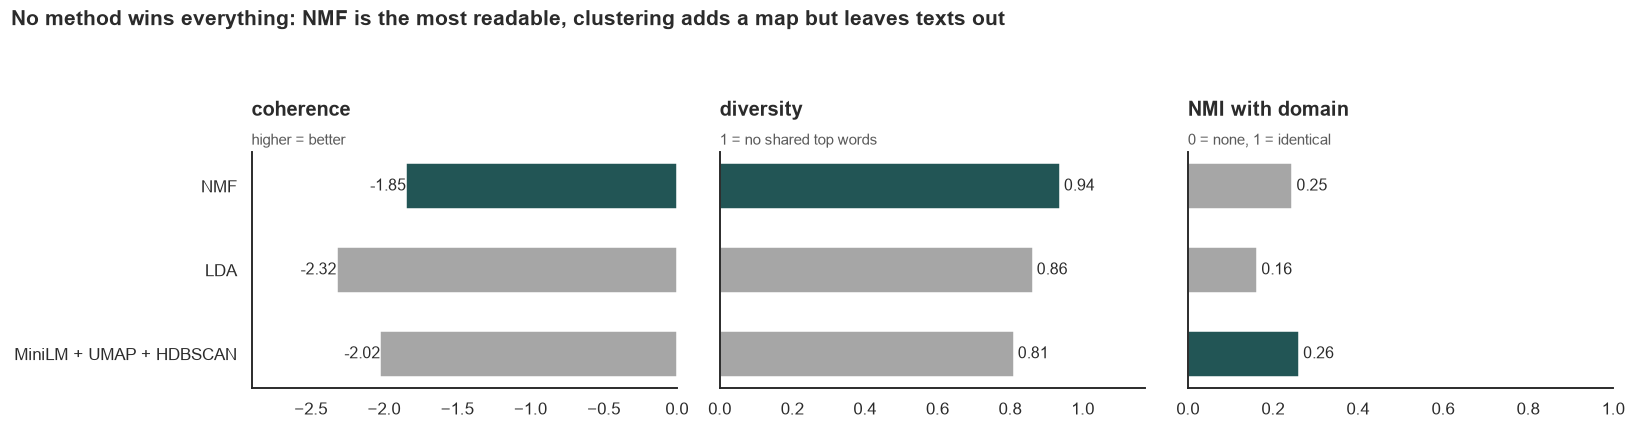

In [76]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, col, note in [(axes[0], "coherence", "higher = better"), (axes[1], "diversity", "1 = no shared top words"),
                      (axes[2], "NMI with domain", "0 = none, 1 = identical")]:
    v = comparison[col]
    colors = [CMP_A if m == v.idxmax() else CMP_B for m in v.index]
    ax.barh(v.index[::-1], v.values[::-1], color=colors[::-1], height=0.55)
    for yi, val in enumerate(v.values[::-1]):
        ax.text(val, yi, f" {val:.2f}", va="center", ha="left" if val >= 0 else "right", fontsize=10.5)
    titles(ax, col, note)
    if col == "coherence":
        ax.set_xlim(v.min() * 1.25, 0)
    else:
        ax.set_xlim(0, max(1, v.max() * 1.25))
fig.suptitle("No method wins everything: NMF is the most readable, clustering adds a map but leaves texts out",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.08)
fig.tight_layout()
save(fig, "16_method_comparison")
plt.show()

No method wins everything. **NMF** has the most coherent and most distinct topics and assigns every incident, so it is the best choice for the story. **LDA** is the weakest on these short texts. **Clustering** finds its own number of groups and gives the map, but leaves 17% of the incidents unassigned. On the map, five NMF topics sit in one area, so the word-based and the meaning-based methods agree on the main themes. Agreement with the official domains is only partial (NMI 0.25 for NMF, 0.26 for clustering, 0.16 for LDA): the text carries part of the type of harm, but not all of it.

## 8. The news reports

The reports are the articles behind the incidents. This export cannot link them back to single incidents, so they are analysed on their own, as a picture of **how AI harm is covered in the media**.

### 8.1 Cleaning the reports

About 10% of the rows have no title, URL, source or authors. First a look at what these rows are.

In [77]:
display(empty_share(rep_raw).to_frame("empty %").T)

empty = rep_raw["Title"].isna()
print("Rows without a title:", empty.sum())
display(rep_raw.loc[empty, "Tags"].value_counts().to_frame("tag of the empty rows"))
rep_raw.loc[empty, "Date Published"].dt.year.value_counts().to_frame("published (year)").T

,Report Number,Title,URL,Source Domain,Date Published,Date Downloaded,Authors,Submitters,Language,Tags,Description,Is Incident Report
empty %,0.0,10.2,10.2,10.2,0.0,0.0,10.2,0.0,0.0,79.5,74.7,0.0


Rows without a title: 812


,tag of the empty rows
Tags,
Variant:Unreviewed,811
Variant:Approved,1


Date Published,1967,1970,2026,2025,2024,2000,2023,2019,2014,2007,1025,2020,2013,2001
published (year),608,143,34,9,5,3,2,2,1,1,1,1,1,1


All the empty rows are tagged *Variant*: these are not news articles but submissions of incident variants. They also carry placeholder dates (1967, 1970 and even the year 1025, stored in Excel as a negative day number), which would distort any timeline. We drop them.

In [78]:
rep = rep_raw[~rep_raw["Tags"].fillna("").str.startswith("Variant")].copy()
print(f"{len(rep):,} reports left; published from {rep['Date Published'].min().date()} to {rep['Date Published'].max().date()}")

dup = rep[rep["URL"].duplicated(keep=False)].sort_values("URL")
print("Reports whose URL appears more than once:", len(dup), "| extra copies:", rep["URL"].duplicated().sum())
dup[["Report Number", "Title", "Source Domain", "Date Published"]].head(6)

7,142 reports left; published from 1996-04-03 to 2026-10-15
Reports whose URL appears more than once: 121 | extra copies: 62


,Report Number,Title,Source Domain,Date Published
4128,4318,SF couple describes feeling 'trapped' riding i...,abc7news.com,2024-02-08
4127,4317,SF couple describes feeling 'trapped' riding i...,abc7news.com,2024-02-08
5091,5281,The Deepfake is a powerful weapon in the war i...,africanarguments.org,2024-10-23
5092,5282,The Deepfake is a powerful weapon in the war i...,africanarguments.org,2024-10-23
5093,5283,The Deepfake is a powerful weapon in the war i...,africanarguments.org,2024-10-23
7126,7319,Two men charged with creating AI-generated por...,apnews.com,2026-05-21


Some articles appear two or three times with consecutive report numbers: the same article was attached to several incidents. Since the reports are used as a picture of media coverage, each article should count once.

In [79]:
rep = rep.drop_duplicates(subset="URL").copy()
rep["year"] = rep["Date Published"].dt.year
rep["text"] = (rep["Title"].fillna("") + ". " + rep["Description"].fillna("")).str.strip(". ")
rep["english"] = rep["Language"] == "en"
rep["kind"] = np.where(rep["Is Incident Report"], "about an incident", "general issue report")

lang = rep["Language"].value_counts(normalize=True) * 100
submit = rep["Submitters"].value_counts(normalize=True) * 100
print(f"{len(rep):,} unique articles")
print(f"English: {lang['en']:.0f}% | next: " + ", ".join(f"{k} {v:.1f}%" for k, v in lang.iloc[1:5].items()))
print(f"Top submitter: {submit.iloc[0]:.0f}% of reports; top 3 together {submit.head(3).sum():.0f}%")
print("General issue reports (not about one incident):", (~rep["Is Incident Report"]).sum())

7,080 unique articles
English: 95% | next: es 1.1%, it 0.4%, de 0.4%, fr 0.4%
Top submitter: 55% of reports; top 3 together 76%
General issue reports (not about one incident): 450


Things to keep in mind for the rest of the section:
* 95% of the articles are in English; the text analysis uses English articles only.
* One person submitted more than half of all articles, so what gets into the database partly reflects the interests of a few contributors.
* About 6% are general *issue* reports (about AI risks, not one incident). They are kept and shown separately in the volume chart.


### 8.2 Volume and sources

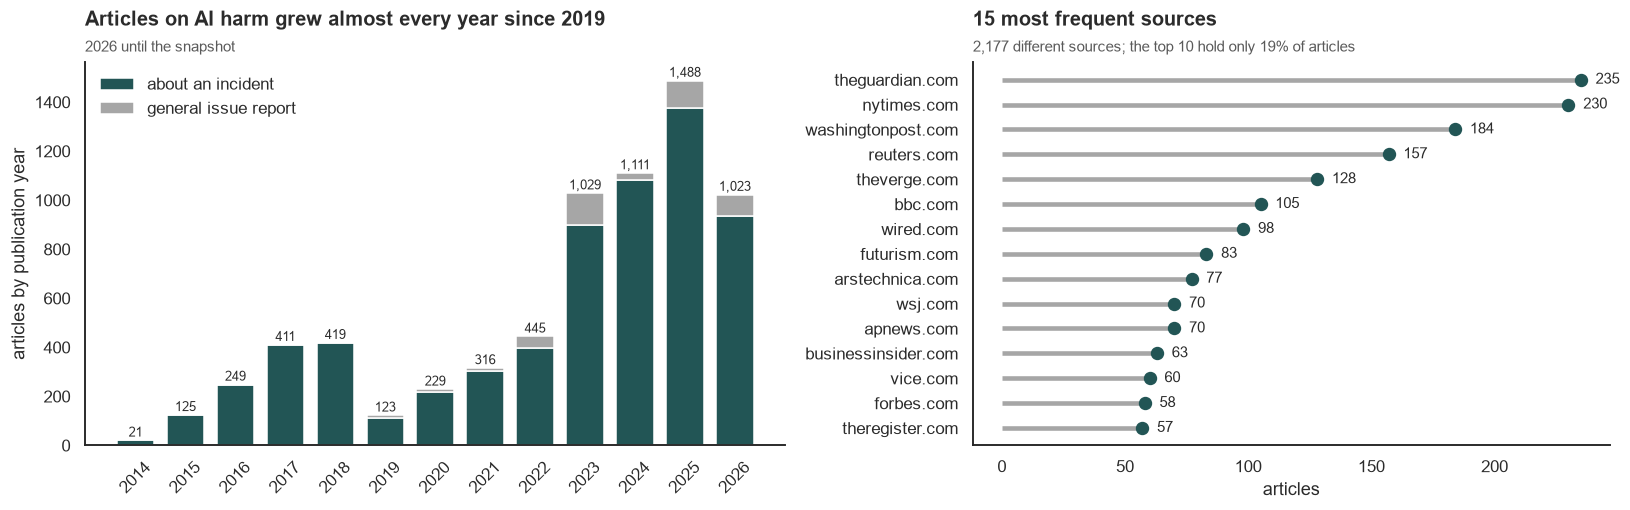

In [80]:
per_year_rep = rep[rep["year"].between(2014, 2026)].groupby(["year", "kind"]).size().unstack(fill_value=0)
sources = rep["Source Domain"].value_counts()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})

bottom = np.zeros(len(per_year_rep))
for col, color in [("about an incident", CMP_A), ("general issue report", CMP_B)]:
    ax[0].bar(per_year_rep.index, per_year_rep[col], bottom=bottom, color=color, width=0.75, label=col)
    bottom += per_year_rep[col].values
for x, v in zip(per_year_rep.index, bottom):
    ax[0].text(x, v + 15, f"{int(v):,}", ha="center", fontsize=8.5)
ax[0].set_xticks(per_year_rep.index)
ax[0].tick_params(axis="x", labelrotation=45)
ax[0].set_ylabel("articles by publication year")
ax[0].legend(loc="upper left")
titles(ax[0], "Articles on AI harm grew almost every year since 2019", "2026 until the snapshot")

top_src = sources.head(15)[::-1]
ax[1].hlines(top_src.index, 0, top_src.values, color=CMP_B, lw=3)
ax[1].scatter(top_src.values, top_src.index, color=CMP_A, s=60, zorder=3)
for y, v in enumerate(top_src.values):
    ax[1].text(v + 6, y, f"{v}", va="center", fontsize=9.5)
ax[1].set_xlabel("articles")
titles(ax[1], "15 most frequent sources",
       f"{len(sources):,} different sources; the top 10 hold only {sources.head(10).sum() / sources.sum():.0%} of articles")

fig.tight_layout()
save(fig, "25_reports_volume_sources")
plt.show()

Coverage is spread over more than 2,000 outlets; no single source dominates. The high numbers in 2017-2018 are most likely a backlog of older articles added by early contributors, not a real peak in coverage.

### 8.3 What the media talks about: keyword themes

A simple and fully transparent view: the share of English article titles that mention a theme, per year. The 8 themes and their word lists are **chosen by hand**, based on the topics and risk domains found in the incident analysis (section 7). Each list holds the obvious terms, main products and companies, and word stems that catch variants (`racis` = racist, racism). We refined the lists by reading titles that matched nothing and fixing false matches (*Tom Cruise* is not the robotaxi company *Cruise*). About a third of the titles still match no theme, so in 8.5 we check the result against a topic model that needs no word lists.

In [81]:
THEMES = {"Deepfakes and scams": r"deepfake|ai-generated|ai generated|nude|porn|sexually explicit|fake (?:image|video|photo|voice)|scam|fraud|impersonat|voice clon|synthetic",
          "Chatbots and assistants": r"chatgpt|chatbot|openai|anthropic|gemini|llm|language model|grok|copilot|claude|character\.ai|replika|alexa|siri|voice assistant|\bbots?\b",
          "Self-driving and robots": r"tesla|waymo|(?<!tom )cruise|self-driving|autopilot|autonomous (?:car|vehicle|driving)|driverless|robotaxi|robot",
          "Surveillance, spyware and hacking": r"facial recognition|face recognition|face id|clearview|surveillance|biometric|spyware|hack|cyberattack|malware|ransomware|paragon|pegasus|phishing",
          "Bias and discrimination": r"bias|discriminat|racis|sexis|gender|unfair|\bblack\b|hate speech",
          "Misinformation and elections": r"misinformation|disinformation|fake news|false information|election|hallucinat|fact.check|robocall|fake (?:cases|citations)",
          "Algorithms and moderation": r"algorithm|recommendation|content moderation|moderator|newsfeed|news feed",
          "Lawsuits, courts and police": r"lawsuit|\bsues?\b|sued|court|class action|judge|arrest|police|charged"}

heads = rep[rep["english"] & rep["year"].between(2016, 2026)].copy()
heads["t"] = heads["Title"].str.lower()
theme_share = pd.DataFrame({k: heads.groupby("year")["t"].apply(lambda s: s.str.contains(p).mean())
                            for k, p in THEMES.items()}) * 100
theme_share.round(0).T

year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Deepfakes and scams,2.0,2.0,1.0,3.0,6.0,3.0,9.0,28.0,39.0,36.0,19.0
Chatbots and assistants,10.0,14.0,1.0,2.0,5.0,8.0,6.0,27.0,15.0,18.0,24.0
Self-driving and robots,41.0,21.0,28.0,22.0,13.0,17.0,19.0,6.0,6.0,3.0,5.0
"Surveillance, spyware and hacking",4.0,11.0,6.0,11.0,12.0,13.0,12.0,6.0,6.0,11.0,7.0
Bias and discrimination,25.0,8.0,12.0,18.0,15.0,11.0,8.0,3.0,2.0,1.0,1.0
Misinformation and elections,0.0,1.0,2.0,1.0,2.0,1.0,5.0,6.0,8.0,6.0,3.0
Algorithms and moderation,3.0,2.0,6.0,14.0,16.0,12.0,6.0,2.0,1.0,0.0,1.0
"Lawsuits, courts and police",6.0,8.0,8.0,12.0,12.0,11.0,10.0,12.0,10.0,11.0,23.0


The words were chosen by hand, so they are checked in three ways: how many titles each word catches, how many titles match no theme at all, and which words are frequent in those unmatched titles.

In [82]:
rows = [(theme, w, heads["t"].str.contains(w).sum())
        for theme, p in THEMES.items() for w in re.split(r"\|(?![^(]*\))", p)]
word_check = pd.DataFrame(rows, columns=["theme", "word", "titles"])
with pd.option_context("display.max_rows", None):
    display(word_check.sort_values(["theme", "titles"], ascending=[True, False]).set_index(["theme", "word"]))

titles
theme                             word                                      
Algorithms and moderation         algorithm                              192
                                  recommendation                           6
                                  moderator                                4
                                  content moderation                       1
                                  newsfeed                                 0
                                  news feed                                0
Bias and discrimination           racis                                  108
                                  bias                                    90
                                  \bblack\b                               80
                                  discriminat                             39
                                  sexis                                   32
                                  gender                                  27
                                  hate speech                             11
                                  unfair                                   7
Chatbots and assistants           chatgpt                                332
                                  chatbot                                300
                                  openai                                 134
                                  grok                                    92
                                  \bbots?\b                               71
                                  anthropic                               64
                                  alexa                                   46
                                  gemini                                  42
                                  claude                                  41
                                  llm                                     16
                                  copilot                                 14
                                  character\.ai                           14
                                  replika                                  7
                                  language model                           6
                                  voice assistant                          3
                                  siri                                     1
Deepfakes and scams               deepfake                               705
                                  scam                                   445
                                  ai-generated                           285
                                  porn                                   166
                                  fake (?:image|video|photo|voice)       126
                                  fraud                                   98
                                  nude                                    97
                                  impersonat                              49
                                  sexually explicit                       11
                                  voice clon                               9
                                  ai generated                             7
                                  synthetic                                5
Lawsuits, courts and police       police                                 202
                                  lawsuit                                155
                                  court                                  136
                                  arrest                                 122
                                  \bsues?\b                              111
                                  judge                                   55
                                  sued                                    35
                                  charged                                 26
                                  class action                    

In [83]:
matched = pd.DataFrame({k: heads["t"].str.contains(p) for k, p in THEMES.items()})
heads["n_themes"] = matched.sum(axis=1)

print(f"Titles with no theme: {(heads['n_themes'] == 0).mean():.0%}   with one: {(heads['n_themes'] == 1).mean():.0%}   "
      f"with two or more: {(heads['n_themes'] >= 2).mean():.0%}")
(heads["n_themes"] == 0).groupby(heads["year"]).mean().mul(100).round(0).to_frame("% of titles with no theme").T

Titles with no theme: 32%   with one: 55%   with two or more: 13%


year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
% of titles with no theme,23.0,36.0,43.0,33.0,39.0,38.0,36.0,27.0,27.0,29.0,34.0


In [84]:
unmatched = heads.loc[heads["n_themes"] == 0, "t"]
cv = CountVectorizer(stop_words="english", min_df=5, ngram_range=(1, 2))
counts = pd.Series(np.asarray(cv.fit_transform(unmatched).sum(axis=0)).ravel(), index=cv.get_feature_names_out())
print("Most frequent words in titles without a theme:")
print(", ".join(f"{w} ({n})" for w, n in counts.sort_values(ascending=False).head(40).items()))
with pd.option_context("display.max_colwidth", None):
    display(heads.loc[heads["n_themes"] == 0, ["year", "Title"]].sample(15, random_state=SEED))

Most frequent words in titles without a theme:
ai (858), fake (111), google (102), new (82), using (75), facebook (67), says (62), amazon (62), video (61), data (61), report (58), use (54), say (48), man (48), used (45), news (44), images (43), using ai (43), intelligence (42), meta (39), users (38), artificial (38), app (37), 000 (37), image (37), claims (36), microsoft (35), artificial intelligence (34), tech (34), tool (34), attack (34), world (33), government (33), people (32), war (32), crash (32), false (31), content (31), sports (31), tweet (30)


,year,Title
4429,2025,G/O Media Is Publishing AI Slop Again
1912,2022,"‘The Least Safe Day’: Rollout of Gun-Detecting AI Scanners in Schools Has Been a ‘Cluster,’ Emails Show"
3575,2024,Google’s ‘Woke’ Image Generator Shows the Limitations of AI
7200,2026,Meta AI alignment director shares her OpenClaw email-deletion nightmare: 'I had to RUN to my Mac mini'
100,2018,Ranking Gmail’s AI Fueled Smart Replies
7304,2026,"10th Circuit orders lawyer to pay $1,000 for faulty AI citations"
3419,2024,Pope Francis warns of ‘perverse’ AI dangers
1532,2022,Startup Pony.ai agrees to automated driving software recall
2600,2023,"Explained: How AI image, voice generators can be a global security threat"
2347,2022,Men are abusing their AI girlfriends and bragging about it on Reddit


A first version left half of the titles without a theme. The frequent words in those titles showed what was missing (lawsuits and police, algorithms and moderation, deepfake porn, voice assistants, spyware). With these added, about a third of the titles match no theme; the rest is spread over small subjects and general words like "AI" or "Google". Words that bring in wrong matches were left out on purpose: "fake" alone (fake reviews), "crash" (stock-market crashes) and "war".

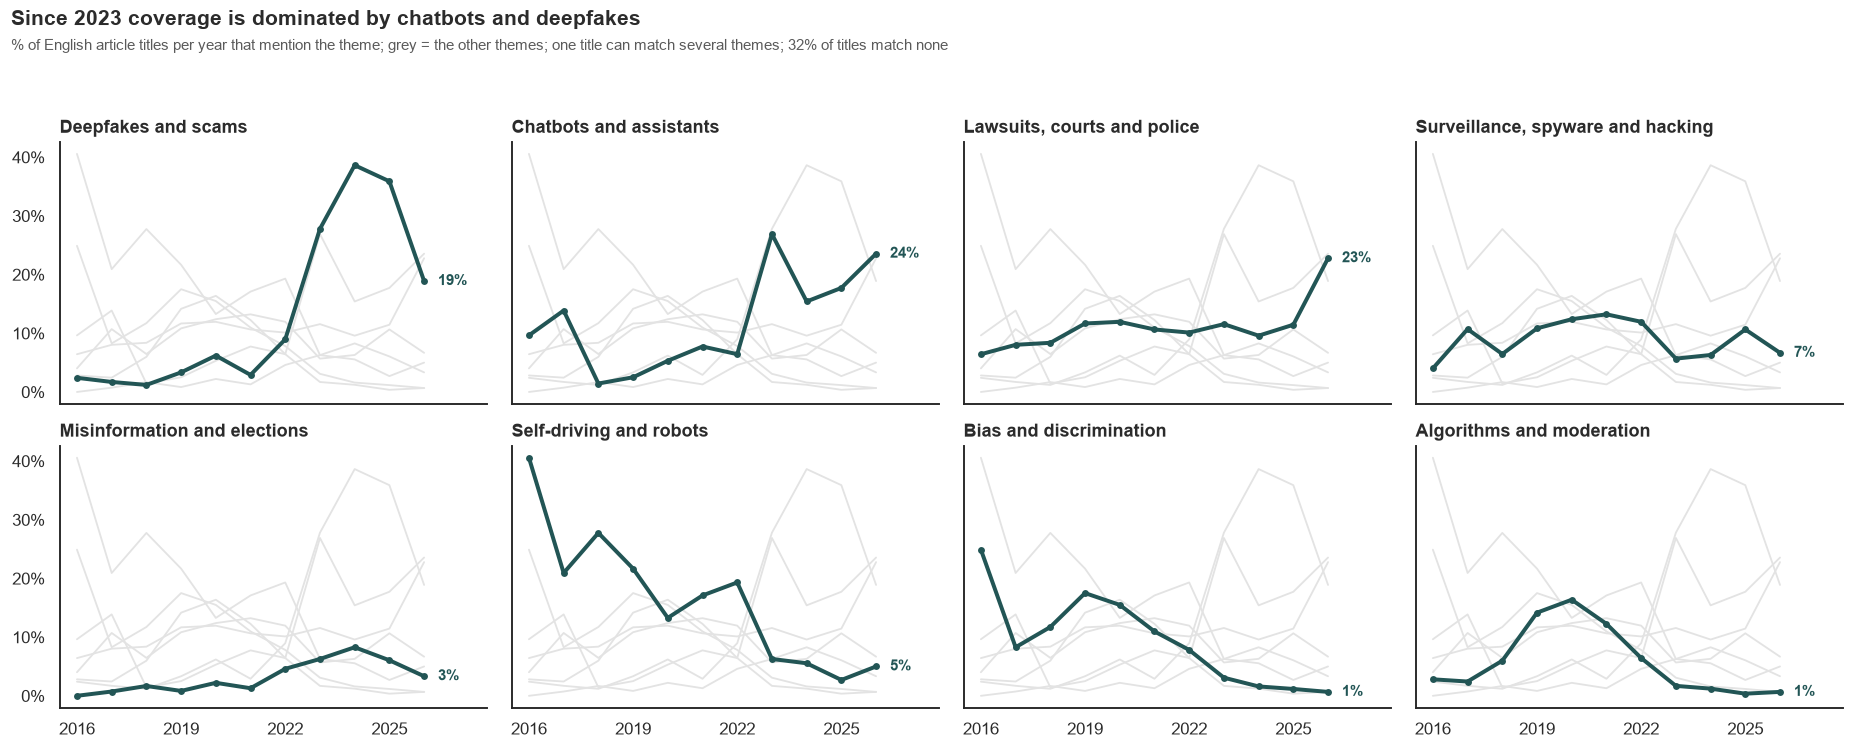

In [85]:
order = theme_share.iloc[-3:].mean().sort_values(ascending=False).index

fig, axes = plt.subplots(2, 4, figsize=(17, 6.6), sharex=True, sharey=True)
for ax, theme in zip(axes.ravel(), order):
    for other in order:
        ax.plot(theme_share.index, theme_share[other], color="#E3E3E3", lw=1.2)
    ax.plot(theme_share.index, theme_share[theme], color=CMP_A, lw=2.6, marker="o", markersize=3.5)
    ax.text(theme_share.index[-1] + 0.4, theme_share[theme].iloc[-1], f"{theme_share[theme].iloc[-1]:.0f}%",
            va="center", fontsize=9.5, color=CMP_A, fontweight="bold")
    ax.set_title(theme, fontsize=11.5)
    ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ax.set_xticks([2016, 2019, 2022, 2025])
    ax.set_xlim(2015.5, 2027.8)
fig.suptitle("Since 2023 coverage is dominated by chatbots and deepfakes", x=0.01, ha="left",
             fontsize=13.5, fontweight="bold", y=1.03)
fig.text(0.01, 0.975, f"% of English article titles per year that mention the theme; grey = the other themes; "
         f"one title can match several themes; {(heads['n_themes'] == 0).mean():.0%} of titles match none", fontsize=9.5, color="#5A5A5A")
fig.tight_layout(rect=(0, 0, 1, 0.96))
save(fig, "26_media_themes")
plt.show()

Each small panel shows one theme in petrol against the others in grey, so the eye can compare without a busy legend. Around 2016-2019 self-driving cars and bias dominated the headlines; since 2023 chatbots and deepfakes/scams have taken over. The rise of lawsuits and police stories in 2026 is a first sign of a legal reaction, but the year is incomplete. The shares do not add up to 100%: titles can match no theme or several.

### 8.4 Topic model of the reports

The keyword themes only find what we expected. As a check, the same NMF as in section 7 looks for the themes by itself in the English titles (plus the description when there is one), the same idea as for the harmed groups in section 2.6: first hand-made rules, then a data-driven method.

Titles are short, so NMF puts many titles without a clear theme into one large leftover topic: its articles have by far the lowest topic weight. We name that topic *mixed, no clear theme*, show it last, and read only the other nine.

In [86]:
r_en = rep[rep["english"] & (rep["text"].str.len() > 25) & rep["year"].between(2014, 2026)].drop_duplicates("Title").copy()
tf_r = TfidfVectorizer(stop_words=STOP + ["says", "say", "report", "reports", "news", "artificial", "intelligence", "technology", "tech"],
                       min_df=8, max_df=0.4, sublinear_tf=True)
X_r = tf_r.fit_transform(r_en["text"])
vocab_r = tf_r.get_feature_names_out()

In [87]:
X_r_cnt = CountVectorizer(vocabulary=tf_r.vocabulary_).fit_transform(r_en["text"])
rows = []
for k in [6, 8, 10, 12, 15]:
    fits = [NMF(k, init="random", random_state=s, max_iter=400).fit(X_r) for s in range(4)]
    labels = [f.transform(X_r).argmax(axis=1) for f in fits]
    tw = top_words(fits[0].components_)
    rows.append({"k": k,
                 "coherence": coherence(tw, X_r_cnt),
                 "diversity": diversity(tw),
                 "stability": np.mean([normalized_mutual_info_score(labels[i], labels[j]) for i in range(4) for j in range(i + 1, 4)])})
pd.DataFrame(rows).set_index("k").round(2)

c:\Users\natal\Dual Degree jupyter\ai-incidents-analysis\.venv\Lib\site-packages\sklearn\decomposition\_nmf.py:1723: ConvergenceWarning: Maximum number of iterations 400 reached. Increase it to improve convergence.
  warnings.warn(


,coherence,diversity,stability
k,,,
6,-2.93,0.97,0.75
8,-3.07,0.94,0.68
10,-2.85,0.93,0.78
12,-2.90,0.93,0.67
15,-2.85,0.89,0.70


As for the incidents, we compare several numbers of topics. k = 10 has the best coherence and the highest stability, and its diversity (0.93) is still high, so we keep **10 topics**. One of them becomes the leftover topic for titles without a clear theme, so nine readable topics remain.

In [88]:
K_R = 10
nmf_r = NMF(K_R, init="nndsvd", random_state=SEED, max_iter=400).fit(X_r)
W_r = nmf_r.transform(X_r)
r_en["topic"] = W_r.argmax(axis=1)
tw_r = top_words(nmf_r.components_, 6)
name_r = {k: ", ".join(vocab_r[tw_r[k][:3]]) for k in range(K_R)}

strength = pd.Series(W_r.max(axis=1)).groupby(r_en["topic"].values).mean()
mixed = strength.idxmin()
name_r[mixed] = "mixed, no clear theme"
size_r = r_en["topic"].value_counts()
size_r = pd.concat([size_r.drop(mixed), size_r[[mixed]]])
print("average topic weight per topic:", strength.round(3).to_dict())
print(f"{len(r_en):,} English articles, {X_r.shape[1]:,} words")
pd.DataFrame({"top words": [", ".join(vocab_r[tw_r[k]]) for k in size_r.index], "articles": size_r.values}, index=size_r.index)

average topic weight per topic: {0: 0.052, 1: 0.113, 2: 0.123, 3: 0.093, 4: 0.086, 5: 0.101, 6: 0.072, 7: 0.036, 8: 0.078, 9: 0.112}
6,535 English articles, 2,107 words


,top words,articles
topic,,
8,"scam, deepfakes, warns, taylor, swift, creuset",610
6,"fake, video, viral, images, trump, obama",600
3,"chatgpt, lawyer, openai, court, cases, shooting",561
0,"deepfake, video, porn, videos, images, scams",497
4,"google, search, image, gemini, black, photos",433
1,"tesla, autopilot, driver, crash, model, police",410
5,"chatbot, musk, elon, grok, hitler, eating",375
9,"driving, self, car, crash, cars, uber",318
2,"recognition, facial, police, face, arrest, sof...",307


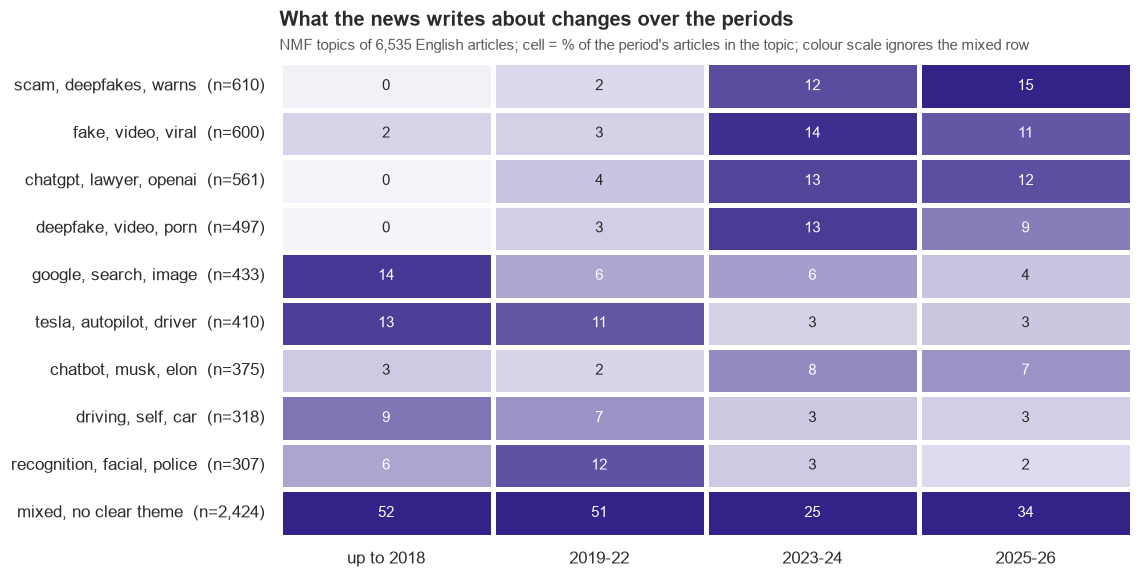

In [89]:
r_en["period"] = pd.cut(r_en["year"], [0, 2018, 2022, 2024, 2026], labels=PERIODS)
by_period_r = pd.crosstab(r_en["topic"], r_en["period"], normalize="columns").loc[size_r.index] * 100

fig, ax = plt.subplots(figsize=(10, 5.6))
sns.heatmap(by_period_r, annot=True, fmt=".0f", cmap=SEQ, cbar=False, ax=ax, linewidths=2, linecolor="white",
            vmax=by_period_r.drop(mixed).values.max(),
            yticklabels=[f"{name_r[k]}  (n={size_r[k]:,})" for k in size_r.index], annot_kws={"fontsize": 9.5})
ax.set_xlabel("")
ax.set_ylabel("")
titles(ax, "What the news writes about changes over the periods",
       f"NMF topics of {len(r_en):,} English articles; cell = % of the period's articles in the topic; colour scale ignores the mixed row")
save(fig, "27_report_topics_by_period")
plt.show()

### 8.5 Do the two methods agree?

For each topic found by NMF we check what share of its article titles matches each keyword theme from 8.3. If the methods agree, each topic should mostly match one theme.

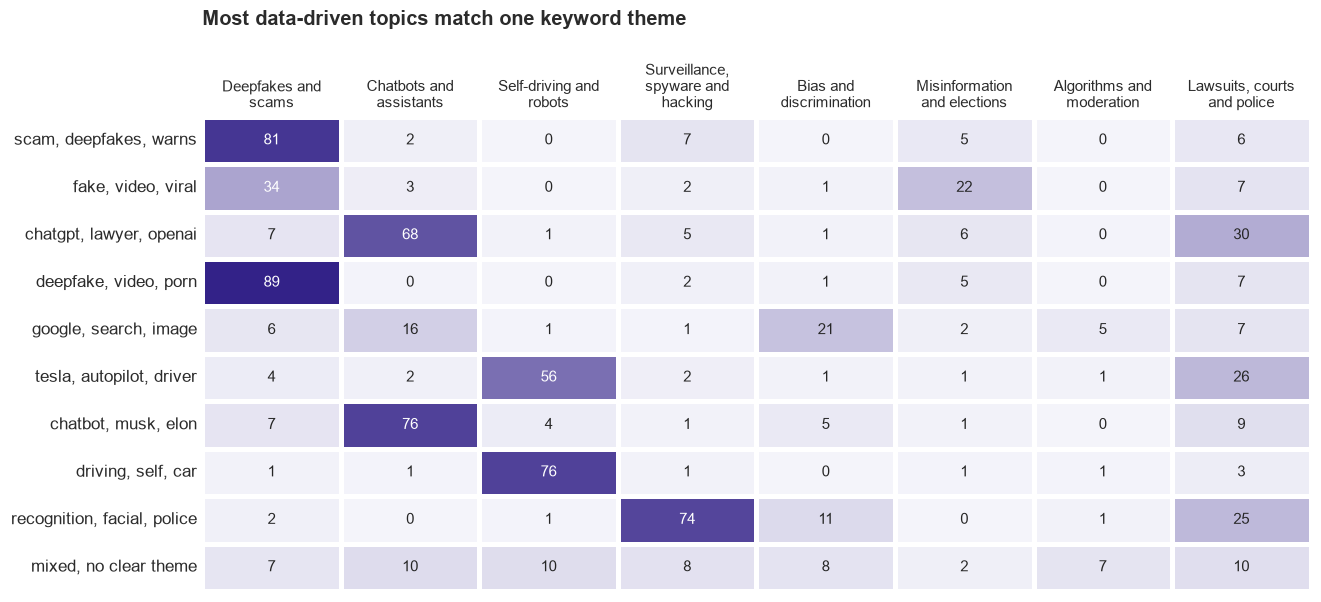

In [90]:
t = r_en["Title"].str.lower()
theme_hits = pd.DataFrame({k: t.str.contains(p) for k, p in THEMES.items()})
overlap = theme_hits.groupby(r_en["topic"]).mean().mul(100).loc[size_r.index]
overlap.index = [name_r[k] for k in overlap.index]

fig, ax = plt.subplots(figsize=(13, 5.6))
sns.heatmap(overlap, annot=True, fmt=".0f", cmap=SEQ, cbar=False, linewidths=2, linecolor="white", ax=ax,
            annot_kws={"fontsize": 9.5})
ax.set_xticklabels([textwrap.fill(c, 16) for c in overlap.columns], rotation=0, fontsize=9.5)
ax.xaxis.tick_top()
ax.tick_params(length=0)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Most data-driven topics match one keyword theme", pad=60)
save(fig, "28_topics_vs_themes")
plt.show()

The two methods agree for most topics: the NMF topics about deepfakes, scams, chatbots, self-driving cars and facial recognition each match one keyword theme. The topic model also finds a subject the keyword lists miss (Google search and image results), and it shows that chatbot, Tesla and facial recognition stories often come as court or police stories. Because a hand-made and a data-driven method lead to the same picture, the shift towards chatbots and deepfakes in the media does not depend on the choice of method, and it mirrors the shift in the incidents themselves.

## 9. Testing the hypotheses

Each hypothesis from the introduction is measured as a share of incidents and compared between **2019-22** and **2025-26** (before the generative-AI boom and the latest period):

* **H1:** share of classified incidents in the domain *malicious use*.
* **H2:** share of incidents whose developer is only a type of actor, not a named company or person (section 5.2).
* **H3:** share of incidents that harm a specific person: a named individual, a public figure or journalist, or a victim of deepfakes, fraud or scams (section 2.6).

For each we report the change in percentage points, a **95% bootstrap interval** (the incidents resampled 2,000 times), a p-value (chi-square test) and **Cohen's h**, the effect size for a difference between two shares (about 0.2 small, 0.5 medium, 0.8 large). The null hypothesis H0 is always that the share did not change; a p-value below 0.05 rejects it, and the sign of the change shows whether it goes the expected way. The intervals cover the uncertainty of the data we have, not the selection bias of the database.

In [91]:
from scipy import stats

def compare_periods(flag, p1="2019-22", p2="2025-26", n_boot=2000):
    a = flag[inc["period"] == p1].dropna().values
    b = flag[inc["period"] == p2].dropna().values
    rng = np.random.default_rng(SEED)
    boot = [rng.choice(b, len(b)).mean() - rng.choice(a, len(a)).mean() for _ in range(n_boot)]
    lo, hi = np.percentile(boot, [2.5, 97.5]) * 100
    p = stats.chi2_contingency([[a.sum(), len(a) - a.sum()], [b.sum(), len(b) - b.sum()]])[1]
    h = 2 * np.arcsin(np.sqrt(b.mean())) - 2 * np.arcsin(np.sqrt(a.mean()))
    return {p1: a.mean() * 100, p2: b.mean() * 100, "change (pp)": (b.mean() - a.mean()) * 100,
            "lo": lo, "hi": hi, "p-value": p, "Cohen's h": h, f"n {p1}": len(a), f"n {p2}": len(b)}

TARGETED = ["Named individuals", "Public figures and journalists", "Victims of deepfakes, fraud, scams"]
flags = {"H1: Harm comes from misuse":
             (inc["domain"] == "Malicious use").astype(float).where(inc["classified"]),
         "H2: Nobody to blame":
             inc["developer_list"].map(only_generic).astype(float),
         "H3: Harm gets personal":
             inc["harmed_groups"].map(lambda groups: any(x in groups for x in TARGETED)).astype(float)}
hyp = pd.DataFrame({name: compare_periods(f) for name, f in flags.items()}).T
hyp = hyp.astype({"n 2019-22": int, "n 2025-26": int})
hyp.round(2)

,2019-22,2025-26,change (pp),lo,hi,p-value,Cohen's h,n 2019-22,n 2025-26
H1: Harm comes from misuse,15.09,56.08,40.98,35.01,46.32,0.0,0.89,318,510
H2: Nobody to blame,16.92,55.85,38.92,33.41,44.31,0.0,0.84,325,727
H3: Harm gets personal,28.92,60.80,31.87,25.80,38.44,0.0,0.65,325,727


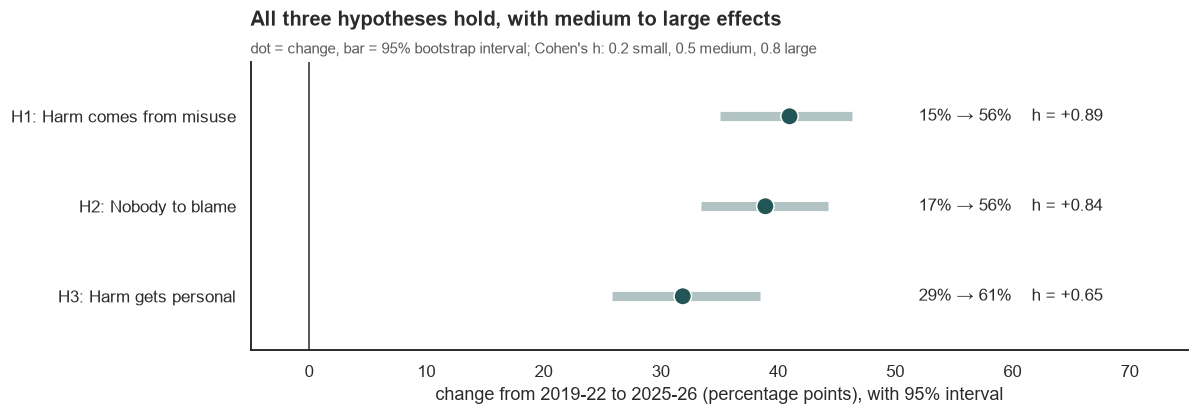

In [92]:
fig, ax = plt.subplots(figsize=(11, 3.4))
y = np.arange(len(hyp))[::-1]
colors = [CMP_A] * len(hyp)
ax.hlines(y, hyp["lo"], hyp["hi"], color=colors, lw=6, alpha=0.35)
ax.scatter(hyp["change (pp)"], y, s=130, color=colors, zorder=3, edgecolor="white")
for yi, (name, r) in zip(y, hyp.iterrows()):
    ax.text(52, yi, f"{r['2019-22']:.0f}% → {r['2025-26']:.0f}%    h = {r["Cohen's h"]:+.2f}", va="center", fontsize=11)
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(y, hyp.index, fontsize=11)
ax.set_xlim(-5, 75)
ax.set_ylim(-0.6, len(hyp) - 0.4)
ax.set_xlabel("change from 2019-22 to 2025-26 (percentage points), with 95% interval")
titles(ax, "All three hypotheses hold, with medium to large effects",
       "dot = change, bar = 95% bootstrap interval; Cohen's h: 0.2 small, 0.5 medium, 0.8 large")
save(fig, "29_hypotheses")
plt.show()

All three hypotheses hold. Between 2019-22 and 2025-26 malicious use grew from 15% to 56% of classified incidents (H1), incidents without a named developer from 17% to 56% (H2), and incidents that harm specific people from 29% to 61% (H3). All intervals are far from zero and the effects are medium to large. Two limits: H1 and H2 are related, because misuse is often done by unknown people, but they answer different questions (what happens vs. who is behind it). H3 depends partly on how the harmed field is written: newer entries name individual people more often, which may reflect the editors as well as the harm.

## 10. Conclusions

All numbers refer to the snapshot of 19 October 2026; 2026 is a partial year.

1. **From AI that breaks to AI that is weaponised (H1).** Malicious use grew from 15% (2019-22) to 56% (2025-26) of classified incidents, while system failures fell from 36% to 10%. The topic models and the incident map find the same shift in the texts alone, and the news coverage follows it: since 2023 headlines are dominated by chatbots, deepfakes and scams.
2. **Nobody to blame (H2).** In 2025-26 more than half of the incidents name no company that built the AI, only a type of tool such as "deepfake technology".
3. **Harm gets personal (H3).** Incidents that harm specific people grew from 29% to 61%, while harm to minorities through biased systems became rare.
4. **Coverage does not explain the shift.** The number of news reports per incident barely depends on the type of harm (epsilon-squared = 0.02).

**Limits.** The AIID is a curated database: it shows what was reported and submitted, not all AI harm. 30% of the 2025-26 incidents have no risk domain yet, the *Named individuals* group is about 12% wrong, and one person submitted more than half of the news reports.

## References

- Mimno, D., Wallach, H., Talley, E., Leenders, M., & McCallum, A. (2011, July). Optimizing semantic coherence in topic models. In Proceedings of the 2011 conference on empirical methods in natural language processing (pp. 262-272).
- Dieng, A. B., Ruiz, F. J., & Blei, D. M. (2020). Topic modeling in embedding spaces. Transactions of the Association for Computational Linguistics, 8, 439-453.
- Greene, D., O’Callaghan, D., & Cunningham, P. (2014, September). How many topics? stability analysis for topic models. In Joint European conference on machine learning and knowledge discovery in databases (pp. 498-513). Berlin, Heidelberg: Springer Berlin Heidelberg.
- Belford, M., Mac Namee, B., & Greene, D. (2018). Stability of topic modeling via matrix factorization. Expert Systems with Applications, 91, 159-169.
- Mahmoud, A. F., Abdalla, F. A., Khamis, G. S. M., Mohammed, Z. M., Gumma, E. A., Adamx, A. M., ... & Hamed, O. M. (2025). A Comparative Evaluation of LDA, NMF, and BERTopic: Analyzing Perplexity and Coherence Metrics. Ingenierie des Systemes d'Information, 30(12), 3163.
- Mihajlov, T., Nešić, M. I., Stanković, R., & Kitanović, O. (2024, September). Topic modeling of the SrpELTeC corpus: A comparison of NMF, LDA, and BERTopic. In 2024 19th conference on computer science and intelligence systems (FedCSIS) (pp. 649-653). IEEE.